In [1]:
import numpy as np
from transformers import AutoTokenizer, AutoModel
import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
import os
import pymanopt
from pymanopt.manifolds import Stiefel
from pymanopt.optimizers import ConjugateGradient
import autograd.numpy as anp
import kagglehub
from pathlib import Path
import json
from tqdm import tqdm
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from IPython.display import display, Markdown

# 0. First loading of news dataset + compute embeddings

The idea is to load the dataset and compute the article embeddings once, then store them in a JSON file. Since this involves a significant amount of computation, it’s best to perform it only once.

https://www.kaggle.com/datasets/rmisra/news-category-dataset/data

> This dataset contains around 210k news headlines from 2012 to 2022 from HuffPost. This is one of the biggest news datasets and can serve as a benchmark for a variety of computational linguistic tasks. HuffPost stopped maintaining an extensive archive of news articles sometime after this dataset was first collected in 2018, so it is not possible to collect such a dataset in the present day. Due to changes in the website, there are about 200k headlines between 2012 and May 2018 and 10k headlines between May 2018 and 2022.

```
@article{misra2022news,
  title={News Category Dataset},
  author={Misra, Rishabh},
  journal={arXiv preprint arXiv:2209.11429},
  year={2022}
}
```

In [2]:
# Download latest version
path = kagglehub.dataset_download("rmisra/news-category-dataset")

print("Path to dataset files:", path)

Path to dataset files: /users/eleves-b/2023/juliette.anglade/.cache/kagglehub/datasets/rmisra/news-category-dataset/versions/3


In [3]:
# Configuration
MODEL_NAME = "answerdotai/ModernBERT-base"
OUTPUT_JSON = './data_narratives/articles_with_embeddings.json'
BATCH_SIZE = 32

def load_model():
    """Load ModernBERT model and tokenizer."""
    print("Loading ModernBERT model...")
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    model = AutoModel.from_pretrained(MODEL_NAME)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)
    model.eval()
    print(f"Model loaded on device: {device}")
    return tokenizer, model, device

def get_embedding(text, tokenizer, model, device):
    """Generate embedding for a single text."""
    inputs = tokenizer(text, return_tensors="pt", truncation=True,
                      max_length=512, padding=True)
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        outputs = model(**inputs)
        embeddings = outputs.last_hidden_state.mean(dim=1)
    return embeddings.cpu().numpy().flatten()

def compute_embeddings_from_kaggle():
    """
    Load articles from Kaggle dataset and compute embeddings.
    Saves results to JSON file.
    """
    # Load model once
    tokenizer, model, device = load_model()
    
    # Load Kaggle dataset
    fname = '.../.cache/kagglehub/datasets/rmisra/news-category-dataset/versions/3' #adapt to your path
    full_path = os.path.join(fname, 'News_Category_Dataset_v3.json')
    
    print(f"Loading dataset from: {full_path}")
    df = pd.read_json(full_path, lines=True)
    print(f"Dataset shape: {df.shape}")
    print(f"Columns: {df.columns.tolist()}")
    
    # Create output directory
    output_dir = Path(OUTPUT_JSON).parent
    output_dir.mkdir(parents=True, exist_ok=True)
    
    # Process articles and compute embeddings
    results = []
    for idx, row in tqdm(df.iterrows(), total=len(df), desc="Computing embeddings"):
        # Combine headline and description
        combined_text = (row.get('headline', '') or '') + ' ' + (row.get('short_description', '') or '')
        combined_text = combined_text.strip()
        
        if not combined_text:
            continue
        
        # Compute embedding
        embedding = get_embedding(combined_text, tokenizer, model, device)
        
        # Store result
        results.append({
            'idx': idx,
            'headline': row.get('headline'),
            'short_description': row.get('short_description'),
            'category': row.get('category'),
            'date': str(row.get('date')),
            'link': row.get('link'),
            'combined_text': combined_text,
            'embedding': embedding.astype(float).tolist()
        })
        
        # Save progressively every 5000 articles
        if (idx + 1) % 5000 == 0:
            print(f"Processed {idx + 1} articles, saving checkpoint...")
            with open(OUTPUT_JSON, 'w', encoding='utf-8') as f:
                json.dump(results, f, ensure_ascii=False, indent=2)
    
    # Final save
    print(f"Saving {len(results)} articles with embeddings...")
    with open(OUTPUT_JSON, 'w', encoding='utf-8') as f:
        json.dump(results, f, ensure_ascii=False, indent=2)
    
    print(f"Completed! Results saved to: {OUTPUT_JSON}")


In [4]:
""" Run only once comment the cell when done to avoid re-computation. """
#compute_embeddings_from_kaggle()

' Run only once comment the cell when done to avoid re-computation. '

# I. Data : news dataset  

Now, we assume that the dataset has been loaded and saved as explained above.

**I.1 dataset**

In [5]:
""" Loading data """
data = pd.read_json("data_narratives/resampled_articles_with_embeddings.json")

<Axes: xlabel='date'>

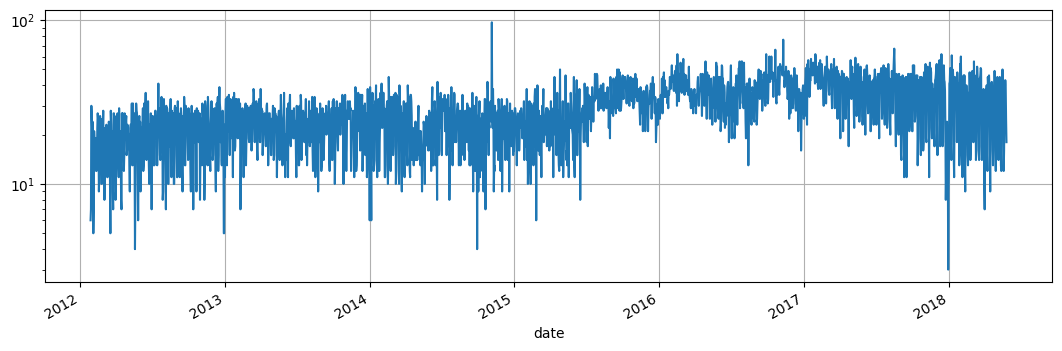

In [6]:
""" Count articles in dataset """
data.groupby('date').category.count().plot(
    figsize=(13,4), grid=True, logy=True,
)

In [7]:
data.category.value_counts()[:7]
data.groupby([data['date'].dt.year, 'category']).size()

date  category     
2012  ENTERTAINMENT      562
      PARENTING         3127
      TRAVEL            3229
2013  ENTERTAINMENT     1015
      PARENTING         4200
      TRAVEL            3384
2014  ENTERTAINMENT     2122
      PARENTING         1350
      POLITICS          3182
      TRAVEL            1861
2015  ENTERTAINMENT     3923
      POLITICS          5887
      TRAVEL             662
2016  ENTERTAINMENT     3526
      POLITICS          9990
      TRAVEL             433
2017  ENTERTAINMENT     3190
      POLITICS         10613
      TRAVEL             246
2018  ENTERTAINMENT     1720
      POLITICS          3067
      TRAVEL              72
dtype: int64

In [8]:
""" display description of dataset in a latex table """

data['year'] = data['date'].dt.year


table = data.groupby(['year', 'category']).size().unstack(fill_value=0)


latex_table = table.to_latex()

print(latex_table)

\begin{tabular}{lrrrr}
\toprule
category & ENTERTAINMENT & PARENTING & POLITICS & TRAVEL \\
year &  &  &  &  \\
\midrule
2012 & 562 & 3127 & 0 & 3229 \\
2013 & 1015 & 4200 & 0 & 3384 \\
2014 & 2122 & 1350 & 3182 & 1861 \\
2015 & 3923 & 0 & 5887 & 662 \\
2016 & 3526 & 0 & 9990 & 433 \\
2017 & 3190 & 0 & 10613 & 246 \\
2018 & 1720 & 0 & 3067 & 72 \\
\bottomrule
\end{tabular}



<Axes: xlabel='date'>

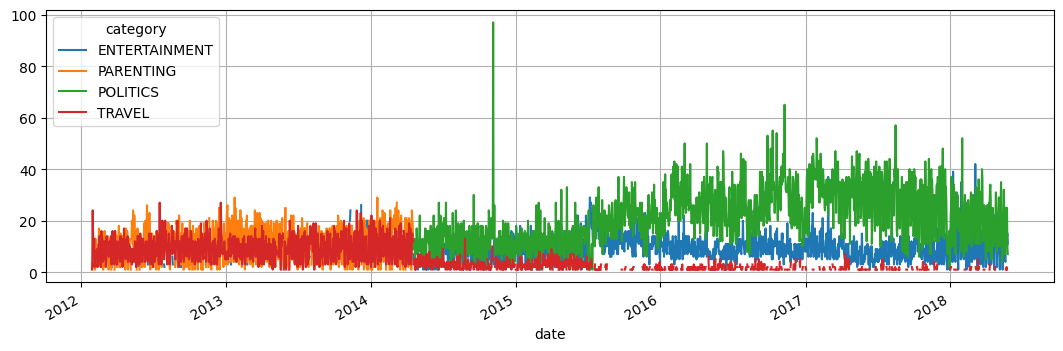

In [9]:
""" Count number of articles per category"""
daily_politics_df = data.groupby(['date', 'category']).link.count().unstack()[:'2018-06-01']
daily_politics_df.plot(
    figsize=(13,4), grid=True, logy=False,
)

In [10]:
""" load the data with embeddings """
data_with_embeddings = pd.read_json("data_narratives/resampled_articles_with_embeddings.json")
#data_with_embeddings.head(5)

**I.2 Resampling**

We are resampling the dataset so that, the number of articles is the same every week. We are keeping the relative proportions of all categories

In [11]:
import pandas as pd
import numpy as np

def resample_constant_weekly(df, target_per_week=None, random_state=42):
    """
    Resample a DataFrame to have a constant number of articles per week,
    while keeping the relative proportions of categories.

    Parameters
    ----------
    df : pd.DataFrame
    target_per_week : int ou None. If None: uses the median number of articles per week.
    random_state : int

    Returns
    -------
    pd.DataFrame : resampled DataFrame 
    """
    df = df.copy()
    df['date'] = pd.to_datetime(df['date'])

    # ── 1. Create week identifier ──────────────────────────
    iso = df['date'].dt.isocalendar()
    df['year_week'] = iso['year'].astype(str) + '-W' + \
                      iso['week'].astype(str).str.zfill(2)

    # ── 2. DDetermine target number per week ───────────────────
    weekly_counts = df.groupby('year_week').size()
    if target_per_week is None:
        target_per_week = int(weekly_counts.median())

    print(f"{'Nombre cible par semaine':<35}: {target_per_week}")
    print(f"{'Nb original — min / médiane / max':<35}: "
          f"{weekly_counts.min()} / {weekly_counts.median():.0f} / {weekly_counts.max()}")

    # ── 3. Resample each week ────────────────────
    rng = np.random.RandomState(random_state)
    resampled_frames = []

    for week, week_df in df.groupby('year_week'):

        # 3a. Proportion of each category this week
        cat_counts      = week_df['category'].value_counts()
        cat_proportions = cat_counts / cat_counts.sum()

        # 3b. Proportional allocation of "target_per_week" budget 
        raw_alloc = cat_proportions * target_per_week
        alloc     = np.floor(raw_alloc).astype(int)

        # 3c. Distribute the remainder to categories with the largest fractional part
        remainder        = target_per_week - alloc.sum()
        fractional_parts = raw_alloc - alloc
        top_cats         = fractional_parts.nlargest(int(remainder)).index
        alloc[top_cats] += 1

        # 3d. Sample from each category according to the allocation
        for cat, n_sample in alloc.items():
            if n_sample == 0:
                continue
            cat_df  = week_df[week_df['category'] == cat]
            replace = n_sample > len(cat_df)         
            sampled = cat_df.sample(n=n_sample, replace= replace,
                                    random_state=rng)
            resampled_frames.append(sampled)

    # ── 4. Concatenate and clean up ───────────────────────────────
    result = pd.concat(resampled_frames, ignore_index=True)
    result.drop(columns=['year_week'], inplace=True)

    return result

In [12]:
#resampled_data = resample_constant_weekly(data)
#resampled_data.head(5)

In [13]:
""" Count articles in dataset """
#resampled_data.groupby('date').category.count().plot(
#    figsize=(13,4), grid=True, logy=True,
#)

' Count articles in dataset '

In [14]:
#resampled_data.groupby([resampled_data['date'].dt.year, 'category']).size()

In [15]:
""" display description of dataset in a latex table """
#resampled_data['year'] = resampled_data['date'].dt.year


#table = resampled_data.groupby(['year', 'category']).size().unstack(fill_value=0)


#latex_table = table.to_latex()

#print(latex_table)

' display description of dataset in a latex table '

## II. Narratives and orthogonalization ##


**I.1 Narratives**

We chose 3 narratives per chapter corresponding to the categories of the news in the dataset

In [16]:
narratives_by_chapter = {
    "politics": {
        "Trump_as_Disruptor_and_Institutional_Stress":
            "Donald Trump rises to and governs from power by channeling widespread distrust of political elites, media institutions, and bureaucratic authority, positioning himself as a disruptive outsider who challenges democratic norms, centralizes executive power, attacks critics, and reframes institutional resistance as partisan sabotage.",
        
        "Culture_War_and_Identity_Conflict":
            "American politics between 2012 and 2018 is structured around intensifying culture wars in which abortion, LGBTQ rights, immigration, race, religion, Confederate symbols, gun control, and voting rights become symbolic battlegrounds through which parties mobilize supporters by framing policy disagreements as existential moral conflicts.",
        
        "Welfare_State_Under_Press":
            "Debates over health care reform, Medicaid, food assistance, drug pricing, refugee policy, and regulatory protections reflect a broader struggle over the future of the American welfare state, as conservative efforts to roll back social protections clash with progressive attempts to defend or expand them in the face of economic insecurity."
    },

    "entertainment": {
        "Entertainment_as_Political_Resistance":
            "Film, television, comedy, and celebrity culture increasingly function as arenas of political contestation, where artists publicly criticize elected officials, late-night shows frame political narratives, awards ceremonies become stages for activism, and cultural production blends entertainment with explicit political messaging.",
        
        "Franchise_Nostalgia_and_Serial_Dominance":
            "The entertainment industry relies heavily on reboots, sequels, cinematic universes, and anniversary revivals, capitalizing on nostalgia and established intellectual property to secure audience loyalty in an era of streaming competition and franchise-driven box office economics.",
        
        "Celebrity_Image_Management_in_the_Social_Media_Age":
            "Celebrities navigate a hyper-visible media ecosystem in which personal relationships, identity declarations, scandals, and social media controversies become central to their public personas, requiring constant image management amid shifting norms around gender, race, and accountability."
    },

    "parenting": {
        "The_Overwhelmed_Modern_Parent":
            "Parenthood in the 2012–2018 period is portrayed as emotionally intense and structurally unsupported, with working parents—especially mothers—struggling to balance careers, childcare costs, sleep deprivation, and social expectations while navigating guilt, burnout, and economic pressure.",
        
        "Intensive_and_Expert_Guided_Parenting":
            "Raising children becomes an increasingly expert-driven project in which parents rely on scientific studies, psychological advice, educational technologies, and developmental optimization strategies to manage screen time, stress, discipline, mental health, and academic performance.",
        
        "Raising_Children_in_a_Politicized_Society":
            "Parents confront a social environment shaped by political polarization, gun violence debates, racial tensions, immigration fears, and changing gender norms, prompting concerns about children’s safety, values formation, civic identity, and exposure to divisive public discourse."
    },
    "travel": {
        "Experiential_and_Transformational_Travel":
            "Travel is framed as a path to self-discovery and cultural immersion, encouraging encounters with remote landscapes, wildlife, historic sites, and local communities as a way to cultivate authenticity, global awareness, and personal growth in an interconnected world.",
        
        "Travel_Optimization_and_Consumer_Strategy":
            "Modern travel is treated as a strategic consumer activity, with emphasis on cheapest destinations, loyalty programs, airline hacks, peak-season timing, gadget recommendations, hotel rankings, and efficiency tips that promise to maximize value, comfort, and status.",
        
        "Aesthetic_and_Instagrammable_Destinations":
            "Destinations are increasingly valued for their visual spectacle and shareability, as pink beaches, dramatic glaciers, themed hotels, architectural landmarks, and unusual experiences become curated backdrops for digital photography and social media performance."
    }
}

**II.2 Orthogonalization**

Our goal is to find a representative $V_i$ of each normalized narrative's embedding $N_i$. We are adding the mean of (N_i)_i as a last "narrative". Thus, we solve the following optimization under constraints problem: 

$$ \text{argmax}_{(V_1, ..., V_n)} \text{min}_{i} N_i^TV_i$$
$$s.t, ||V_i|| \le 1, N_i^TV_i \ge 0, V_i^TV_j = 0$$

In [17]:
def gram_schmidt(N_matrix):
    """Orthogonalization - Gram-Schmidt."""
    n, dim = N_matrix.shape
    V = np.zeros_like(N_matrix, dtype=float)

    for i in range(n):
        v = N_matrix[i].copy().astype(float)
        for j in range(i):
            v -= np.dot(v, V[j]) * V[j]
        norm = np.linalg.norm(v)
        V[i] = v / norm if norm > 1e-10 else v

    return V

In [18]:
def stiefel_optimize(N_matrix, softmin_temp=0.05, max_iter=300):
    """
    Optimization on Stiefel manifold.
    Maximizes min_i <N_i, V_i> avec V @ V.T = I.
    """
    n, dim = N_matrix.shape

    # Stiefel manifold
    manifold = Stiefel(dim, n)

    @pymanopt.function.autograd(manifold)
    def cost(V):
        Vt = V.T
        projections = anp.sum(N_matrix * Vt, axis=1)
        softmin = -softmin_temp * anp.log(anp.sum(anp.exp(-projections / softmin_temp)))
        return -softmin

    problem = pymanopt.Problem(manifold, cost)
    optimizer = ConjugateGradient(verbosity=1, max_iterations=max_iter)

    # Initialization with Gram-Schmidt
    V_init = gram_schmidt(N_matrix).T
    result = optimizer.run(problem, initial_point=V_init)

    return result.point.T, result

In [19]:
def procrustes_stiefel(N_matrix):
    """
    Closed-form solution to the Procrustes problem
    Maximizes sum_i <N_i, V_i> (= minimizes sum_i ||N_i - V_i||^2) under the constraint V @ V.T = I.
    """
    n, dim = N_matrix.shape
    N = N_matrix.T 

    U, S, Wt = np.linalg.svd(N, full_matrices=False)  # U: (dim, n), Wt: (n, n)
    V = U @ Wt

    return V.T  # (n, dim), lignes orthonormées

# III. Compute the narratives and orthogonal representatives 

The narratives need to be normalized before the orthogonalization, bacause we are optimizing on the dot product thus, if the norm of one $N_i$ is arbitrarly bigger than the others, this is inducing a bias. As our metric will be cosine similarity, we don't care about the norm. 

In [20]:
""" To compute embeddings with ModernBERT """

def load_model(model_name="answerdotai/ModernBERT-base"):
    tokenizer = AutoTokenizer.from_pretrained(model_name)
    model = AutoModel.from_pretrained(model_name)
    model.eval()
    return tokenizer, model

def get_embedding(text, tokenizer, model, device):
    """
    Generate embedding for a given text using ModernBERT.
    Uses mean pooling of the last hidden state.
    """
    # Tokenize and prepare input
    inputs = tokenizer(text, return_tensors="pt", truncation=True,
                      max_length=512, padding=True)
    inputs = {k: v.to(device) for k, v in inputs.items()}

    # Get embeddings
    with torch.no_grad():
        outputs = model(**inputs)
        # Mean pooling
        embeddings = outputs.last_hidden_state.mean(dim=1)

    return embeddings.cpu().numpy().flatten()

In [21]:
chapter_names = narratives_by_chapter.keys()

In [22]:
""" Compute narratives embeddings and solve orthogonality problem """
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tokenizer = AutoTokenizer.from_pretrained("answerdotai/ModernBERT-base")
model = AutoModel.from_pretrained("answerdotai/ModernBERT-base").to(device)
model.eval()

narrative_rows = []
for chapter, narratives in narratives_by_chapter.items():
    for title, text in narratives.items():
        narrative_rows.append({"chapter": chapter, "title": title, "text": text})

narrative_matrix_unorm = np.array([get_embedding(row["text"], tokenizer, model, device) for row in narrative_rows])
narrative_matrix = np.array([narrative_matrix_unorm[i] / np.linalg.norm(narrative_matrix_unorm[i]) for i in range(len(narrative_matrix_unorm))])


""" normalize each narrative"""
print(narrative_matrix.shape)

orthogonal_matrix, score = stiefel_optimize(narrative_matrix)

/users/eleves-b/2023/juliette.anglade/Desktop/Code/myenv/lib64/python3.9/site-packages/networkx/utils/backends.py:135: RuntimeWarning: networkx backend defined more than once: nx-loopback
  backends.update(_get_backends("networkx.backends"))
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)
huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disablin

(12, 768)
Optimizing...
Terminated - min grad norm reached after 64 iterations, 0.07 seconds.



In [23]:
narratives = pd.DataFrame([{**narrative_rows[i], "embedding": narrative_matrix[i]} for i in range(len(narrative_rows))])
narratives_orth = pd.DataFrame([{"chapter": narrative_rows[i]["chapter"], "title": f"{narrative_rows[i]['title']}_orth", "text": narrative_rows[i]["text"], "embedding": orthogonal_matrix[i]} for i in range(len(narrative_rows))])

narratives.to_csv("./data_narratives/narratives.csv", index=False)
narratives_orth.to_csv("./data_narratives/narratives_orth.csv", index=False)

In [24]:
narrative_names = (narratives.chapter + ':' + narratives.title).to_list()

orthogonal_names = (narratives_orth.chapter + ':' + narratives_orth.title).to_list()


**III.2 Visualization**

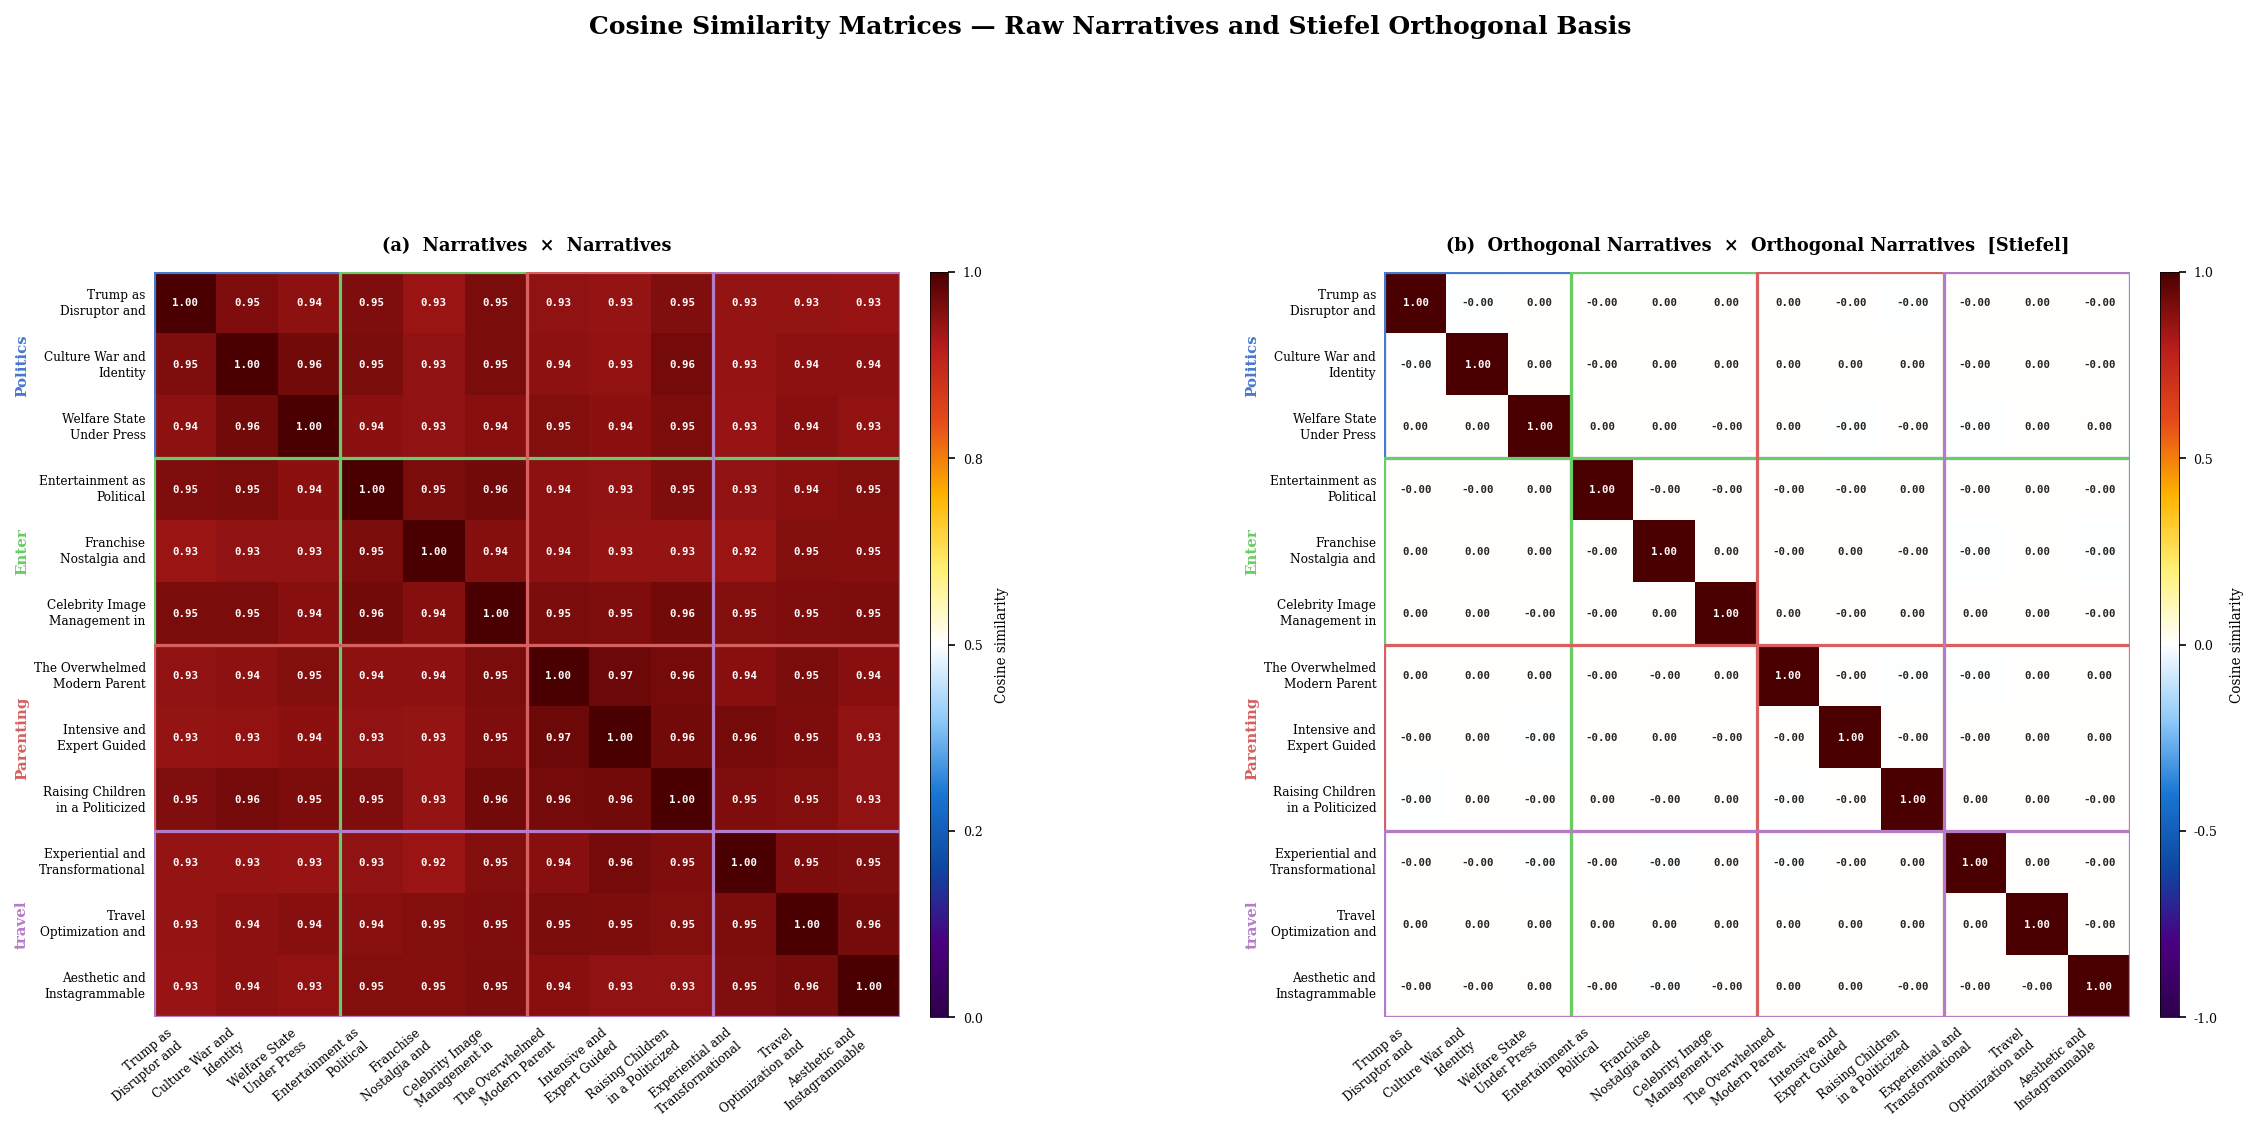

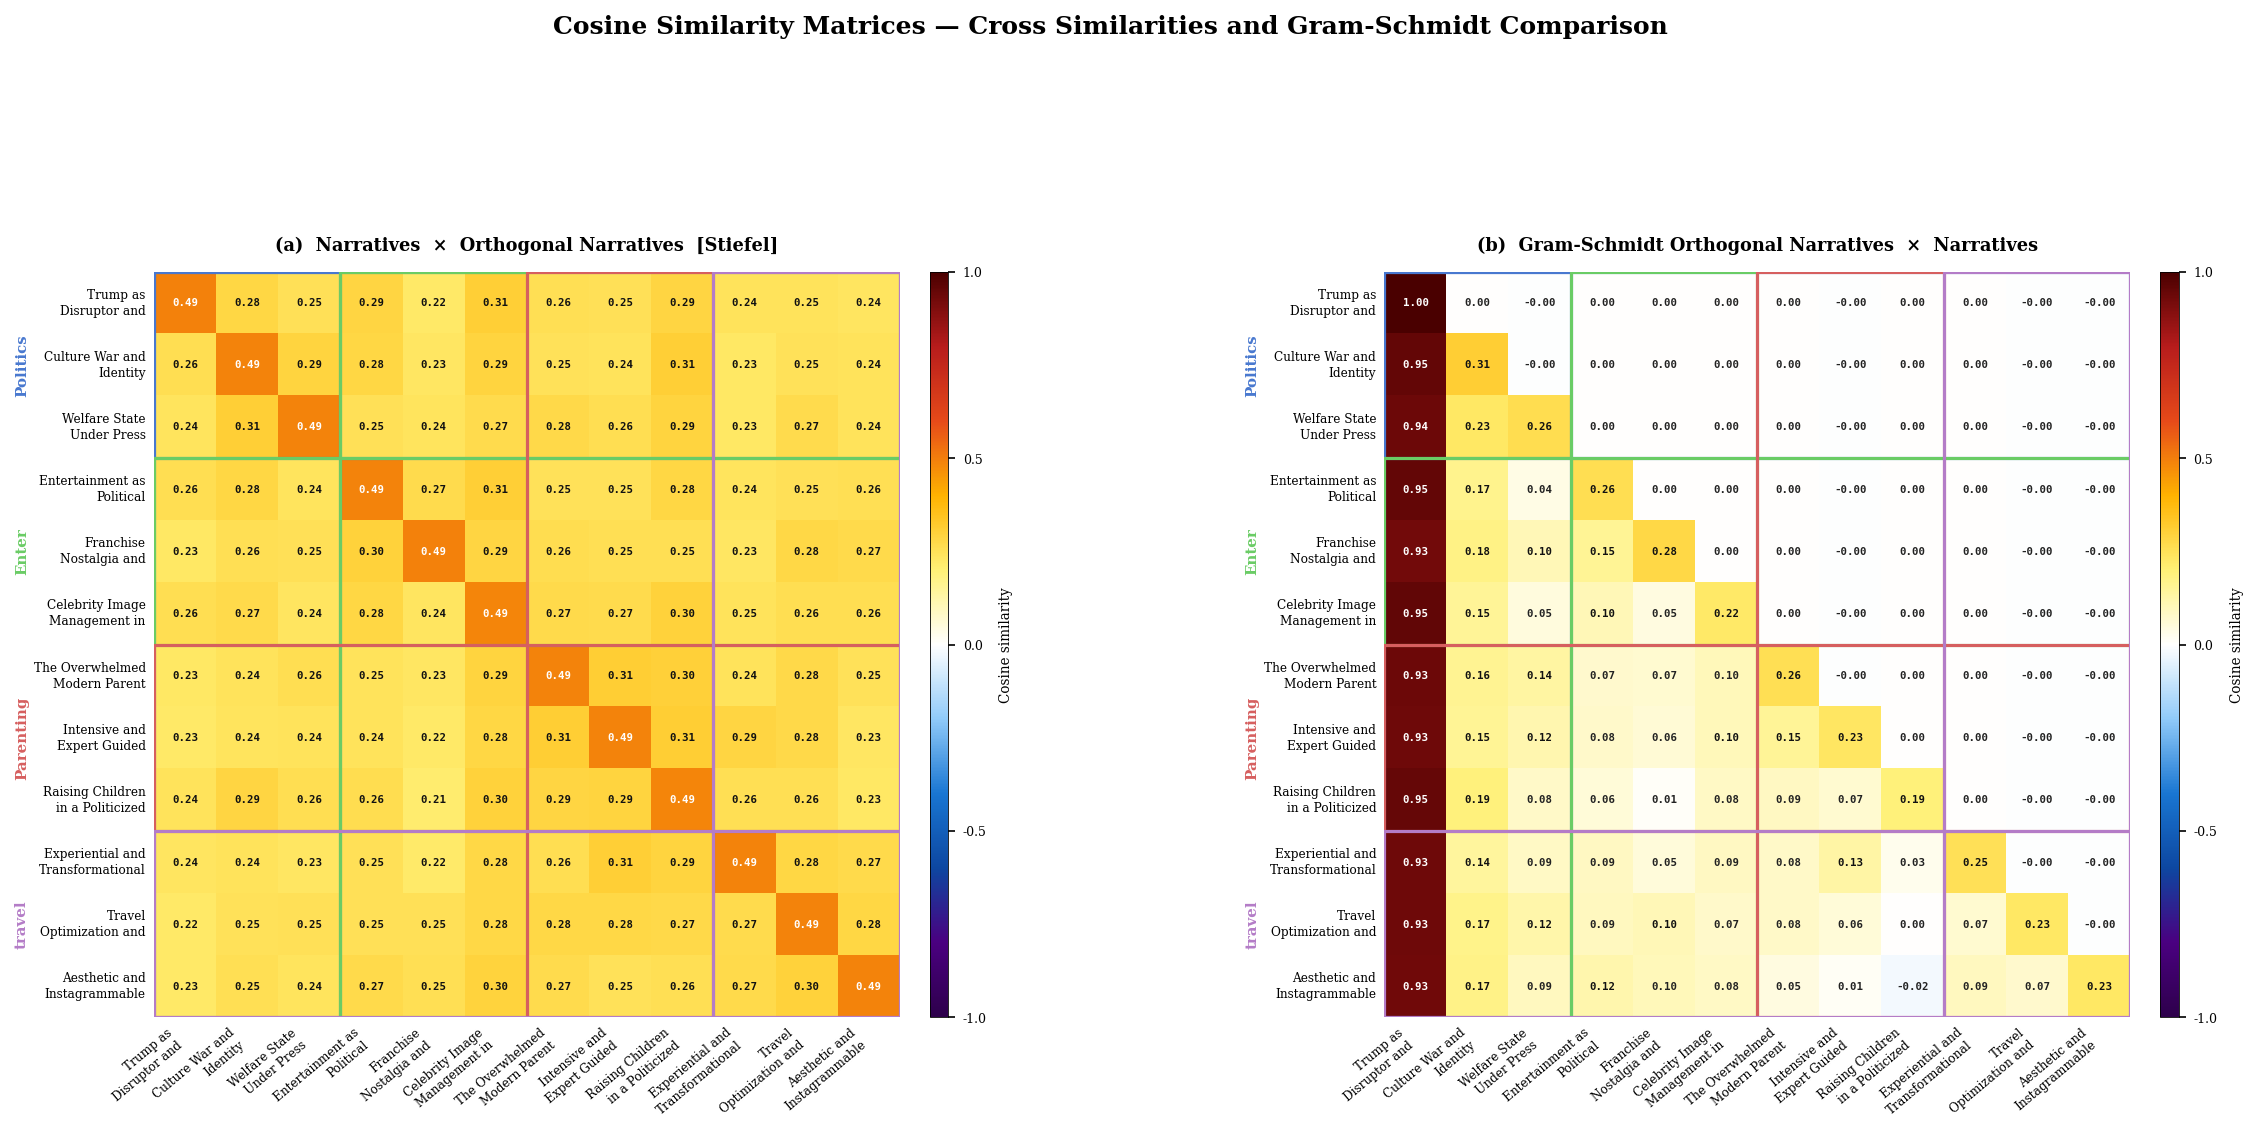

✓  Two figures saved as PDF and PNG.


In [25]:
cosine_sim_all = cosine_similarity(np.vstack([narrative_matrix, orthogonal_matrix]))



# ── 0.  Global aesthetic settings ─────────────────────────────────────────────
plt.rcParams.update({
    "font.family":        "serif",
    "font.serif":         ["Times New Roman", "DejaVu Serif"],
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "axes.spines.left":   False,
    "axes.spines.bottom": False,
    "figure.dpi":         150,
    "savefig.dpi":        300,
})

CMAP = LinearSegmentedColormap.from_list(
    "spectral_contrast",
    [
        "#2d004b",
        "#4a0080",
        "#0d47a1",
        "#1976d2",
        "#90caf9",
        "#ffffff",
        "#fff176",
        "#ffb300",
        "#e64a19",
        "#b71c1c",
        "#4a0000",
    ],
    N=512
)

CHAPTER_PAL = {
    "politics":                 "#4878CF",
    "entertainment": "#6ACC65",
    "parenting":             "#D65F5F",
    "travel":               "#B47CC7",
}

_ABBREV = {
    "politics":                 "Politics",
    "entertainment": "Enter",
    "parenting":             "Parenting",
    "travel":               "travel",
}

# ── 1.  Labels ─────────────────────────────────────────────────────────────────
#chapters      = [row["chapter"] for row in rows]
#titles_raw    = [row["title"]   for row in rows]
chapters =  narratives.chapter.to_list()
titles_raw = narratives.title.to_list()
chapter_names = list(narratives_by_chapter.keys())
chapter_size  = len(narratives_by_chapter["politics"])  # 3
n             = len(narratives_by_chapter)   # 12

def short(title, maxw=16):
    words = title.replace("_", " ").split()
    lines, cur = [], []
    for w in words:
        if sum(len(x) + 1 for x in cur) + len(w) > maxw:
            lines.append(" ".join(cur))
            cur = [w]
        else:
            cur.append(w)
    if cur:
        lines.append(" ".join(cur))
    return "\n".join(lines[:2])

tick_labels = [short(t) for t in titles_raw]

# ── 2.  Similarity matrices ────────────────────────────────────────────────────
sim_NN    = cosine_similarity(narrative_matrix,  narrative_matrix)
sim_N_ON  = cosine_similarity(narrative_matrix,  orthogonal_matrix)
sim_ON_ON = cosine_similarity(orthogonal_matrix, orthogonal_matrix)
sim_GS    = cosine_similarity(gram_schmidt(narrative_matrix), narrative_matrix)

# ── 3.  Core drawing function ──────────────────────────────────────────────────
def draw_heatmap(ax, matrix, row_labels, col_labels, title,
                 vmin=-1, vmax=1, annot=True):

    nr, nc = matrix.shape

    # Background chapter shading
    for i, ch in enumerate(chapter_names):
        c = CHAPTER_PAL[ch]
        ax.add_patch(mpatches.Rectangle(
            (-0.5, i * chapter_size - 0.5), nc, chapter_size,
            color=c, alpha=0.08, linewidth=0, zorder=0
        ))
        ax.add_patch(mpatches.Rectangle(
            (i * chapter_size - 0.5, -0.5), chapter_size, nr,
            color=c, alpha=0.08, linewidth=0, zorder=0
        ))

    # Normalisation
    if vmin == 0:
        display_matrix = matrix * 2 - 1
    else:
        display_matrix = matrix
    norm = TwoSlopeNorm(vmin=-1, vcenter=0.0, vmax=1)

    # ── KEY CHANGE: aspect="equal" forces square cells ────────────────────────
    im = ax.imshow(display_matrix, cmap=CMAP, norm=norm,
                   aspect="equal", interpolation="none", zorder=1)

    # Chapter block borders
    for i, ch in enumerate(chapter_names):
        c = CHAPTER_PAL[ch]
        s = i * chapter_size
        ax.add_patch(mpatches.Rectangle(
            (-0.5, s - 0.5), nc, chapter_size,
            edgecolor=c, facecolor="none",
            linewidth=1.5, zorder=3, alpha=1.0
        ))
        ax.add_patch(mpatches.Rectangle(
            (s - 0.5, -0.5), chapter_size, nr,
            edgecolor=c, facecolor="none",
            linewidth=1.5, zorder=3, alpha=1.0
        ))

    # White separators
    for k in range(1, n // chapter_size):
        pos = k * chapter_size - 0.5
        ax.axvline(pos, color="white", lw=2.0, zorder=4)
        ax.axhline(pos, color="white", lw=2.0, zorder=4)

    # Cell annotations
    if annot:
        for i in range(nr):
            for j in range(nc):
                v = matrix[i, j]
                if v < -0.20:
                    fg = "white"
                elif v < 0.10:
                    fg = "#222222"
                elif v < 0.38:
                    fg = "#111111"
                else:
                    fg = "white"
                ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                        fontsize=5.2, color=fg, fontfamily="monospace",
                        fontweight="bold", zorder=5)

    # Tick labels
    ax.set_xticks(range(nc))
    ax.set_xticklabels(col_labels, fontsize=5.8, rotation=40,
                       ha="right", va="top", linespacing=1.3)
    ax.set_yticks(range(nr))
    ax.set_yticklabels(row_labels, fontsize=5.8, va="center",
                       linespacing=1.3)
    ax.tick_params(length=0, pad=4)

    # Chapter labels — y-axis only
    for i, ch in enumerate(chapter_names):
        mid  = i * chapter_size + (chapter_size - 1) / 2
        col  = CHAPTER_PAL[ch]
        name = _ABBREV[ch]
        ax.annotate(
            name,
            xy=(-0.5, mid), xycoords="data",
            xytext=(-60, 0), textcoords="offset points",
            ha="right", va="center",
            fontsize=7.2, fontweight="bold", color=col,
            annotation_clip=False,
            rotation=90
        )

    # Centred title
    ax.set_title(title, fontsize=8.5, fontweight="bold",
                 pad=10, loc="center")

    ax.set_xlim(-0.5, nc - 0.5)
    ax.set_ylim(nr - 0.5, -0.5)

    return im


def add_colorbar(fig, im, ax, vmin, vmax):
    cbar_ax = ax.inset_axes([1.04, 0.0, 0.025, 1.0])
    ticks   = np.linspace(vmin, vmax, 5)
    cb = fig.colorbar(im, cax=cbar_ax, ticks=np.linspace(-1, 1, 5))
    cb.ax.set_yticklabels([f"{v:.1f}" for v in ticks], fontsize=6)
    cb.set_label("Cosine similarity", fontsize=6.5, labelpad=6)
    cb.outline.set_linewidth(0.4)


# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 1  —  (a) N × N   |   (b) ON × ON  [Stiefel]
# ══════════════════════════════════════════════════════════════════════════════
fig1, axes1 = plt.subplots(
    1, 2,
    figsize=(17, 8),
    gridspec_kw={"wspace": 0.65}
)

panels_fig1 = [
    (axes1[0], sim_NN,    tick_labels, tick_labels,
     "(a)  Narratives  ×  Narratives",
     0,  1),
    (axes1[1], sim_ON_ON, tick_labels, tick_labels,
     "(b)  Orthogonal Narratives  ×  Orthogonal Narratives  [Stiefel]",
     -1, 1),
]

for ax, mat, rl, cl, title, vmin, vmax in panels_fig1:
    im = draw_heatmap(ax, mat, rl, cl, title, vmin=vmin, vmax=vmax)
    add_colorbar(fig1, im, ax, vmin, vmax)

fig1.suptitle(
    "Cosine Similarity Matrices — Raw Narratives and Stiefel Orthogonal Basis",
    fontsize=12, fontweight="bold", y=1.02
)
fig1.savefig("fig1_N_and_ON.pdf", bbox_inches="tight")
fig1.savefig("fig1_N_and_ON.png", bbox_inches="tight", dpi=300)


# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 2  —  (a) N × ON  [Stiefel]   |   (b) GS-ON × N  [Gram-Schmidt]
# ══════════════════════════════════════════════════════════════════════════════
fig2, axes2 = plt.subplots(
    1, 2,
    figsize=(17, 8),
    gridspec_kw={"wspace": 0.65}
)

panels_fig2 = [
    (axes2[0], sim_N_ON,  tick_labels, tick_labels,
     "(a)  Narratives  ×  Orthogonal Narratives  [Stiefel]",
     -1, 1),
    (axes2[1], sim_GS.T,  tick_labels, tick_labels,
     "(b)  Gram-Schmidt Orthogonal Narratives  ×  Narratives",
     -1, 1),
]

for ax, mat, rl, cl, title, vmin, vmax in panels_fig2:
    im = draw_heatmap(ax, mat, rl, cl, title, vmin=vmin, vmax=vmax)
    add_colorbar(fig2, im, ax, vmin, vmax)

fig2.suptitle(
    "Cosine Similarity Matrices — Cross Similarities and Gram-Schmidt Comparison",
    fontsize=12, fontweight="bold", y=1.02
)
fig2.savefig("fig2_cross_and_GS.pdf", bbox_inches="tight")
fig2.savefig("fig2_cross_and_GS.png", bbox_inches="tight", dpi=300)

plt.show()
print("✓  Two figures saved as PDF and PNG.")

**III.3 Example with other narratives**

Let's choose narratives that are independent from our data base to put in evidence the interest of our method compared to Gram Schmidt method 

In [26]:
narratives_by_chapter2 = {
    "climate": {
        "Extreme_Heat_and_Emergency_Policy_Response":
            "Record-breaking temperatures across southern Europe this summer triggered unprecedented heatwaves, forcing governments to activate emergency climate plans and accelerate the transition toward renewable energy sources in order to meaningfully reduce carbon emissions and limit further global warming.",

        "International_Climate_Commitments_Under_Pressure":
            "As climate-related disasters multiply worldwide, the United Nations urgently calls for stronger adherence to the Paris Agreement, emphasizing that industrialized nations must deliver substantial and verifiable reductions in greenhouse gas emissions before irreversible climate tipping points are reached.",

        "Rising_Seas_and_Coastal_Vulnerability":
            "The accelerating melting of Arctic glaciers, driven by sustained global warming, is causing a gradual but measurable rise in sea levels that threatens tens of millions of people living in low-lying coastal zones, according to a major scientific report released this week."
    },

    "artificial_intelligence": {
        "AI_Disruption_of_Labor_Markets":
            "The rapid rise of generative artificial intelligence models is profoundly reshaping global labor markets, prompting technology companies to invest billions of dollars in autonomous systems capable of gradually replacing skilled workers across a wide range of industries and professional sectors.",

        "Big_Tech_Race_and_Regulatory_Pushback":
            "Silicon Valley's leading technology firms are intensifying their competition in artificial intelligence by unveiling increasingly powerful language models, while European regulators work to constrain these developments through strict legislative frameworks designed to protect citizens' fundamental rights and digital freedoms.",

        "AI_Ethics_Privacy_and_Public_Sector_Governance":
            "Recent breakthroughs in artificial intelligence are raising critical ethical concerns around personal data privacy and cybersecurity, prompting several national governments to establish dedicated regulatory frameworks governing the deployment of these technologies within public institutions and essential services."
    },

    "geopolitics": {
        "NATO_Eastern_Flank_and_the_Russia_Ukraine_War":
            "The ongoing military conflict between Russia and Ukraine continues to destabilize the European geopolitical order, compelling NATO allies to reinforce their eastern flank with additional troops and to significantly increase national defense budgets in response to sustained and escalating Russian aggression.",

        "Middle_East_Conflict_and_Humanitarian_Crisis":
            "The armed conflict in the Middle East has triggered a humanitarian catastrophe of alarming proportions, prompting urgent international calls for an immediate ceasefire and the rapid deployment of emergency aid to civilian populations trapped in active combat zones across the region.",

        "US_China_Rivalry_and_Indo_Pacific_Tensions":
            "Growing geopolitical rivalry between Washington and Beijing over the status of Taiwan is seriously threatening stability across the Indo-Pacific region, with both superpowers escalating military demonstrations and economic sanctions in what increasingly resembles a renewed cold war confrontation."
    },

    "economics": {
        "Inflation_Interest_Rates_and_Household_Strain":
            "Persistent inflation across the world's major economies is forcing central banks to maintain elevated interest rates, placing significant pressure on economic growth and disproportionately burdening lower-income households struggling to absorb the rising cost of everyday goods and essential services.",

        "Financial_Market_Volatility_and_Fed_Signaling":
            "Global financial markets experienced sharp volatility this week as investors reacted to the latest monetary policy signals from the United States Federal Reserve, triggering significant fluctuations across major stock indices and a notable depreciation of several emerging market currencies.",

        "IMF_Forecasts_and_Global_Growth_Slowdown":
            "Global economic growth is decelerating at a concerning pace according to the latest International Monetary Fund projections, which identify trade tensions, rising public debt levels, and slowing emerging market performance as the primary drivers behind deteriorating worldwide economic prospects."
    }
}

In [27]:
""" Compute narratives embeddings and solve orthogonality problem """
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tokenizer = AutoTokenizer.from_pretrained("answerdotai/ModernBERT-base")
model = AutoModel.from_pretrained("answerdotai/ModernBERT-base").to(device)
model.eval()

rows = []
for chapter, narratives in narratives_by_chapter2.items():
    for title, text in narratives.items():
        rows.append({"chapter": chapter, "title": title, "text": text})

narrative_matrix_unorm = np.array([get_embedding(row["text"], tokenizer, model, device) for row in rows])

""" normalize each narrative"""
narrative_matrix2 = np.array([narrative_matrix_unorm[i] / np.linalg.norm(narrative_matrix_unorm[i]) for i in range(len(narrative_matrix_unorm))])

orthogonal_matrix2, score = stiefel_optimize(narrative_matrix2)

#orthogonal_matrix_GS2 = gram_schmidt(narrative_matrix2)

orthogonal_matrix_GS2 = procrustes_stiefel(narrative_matrix2)

Optimizing...
Terminated - min grad norm reached after 55 iterations, 0.03 seconds.



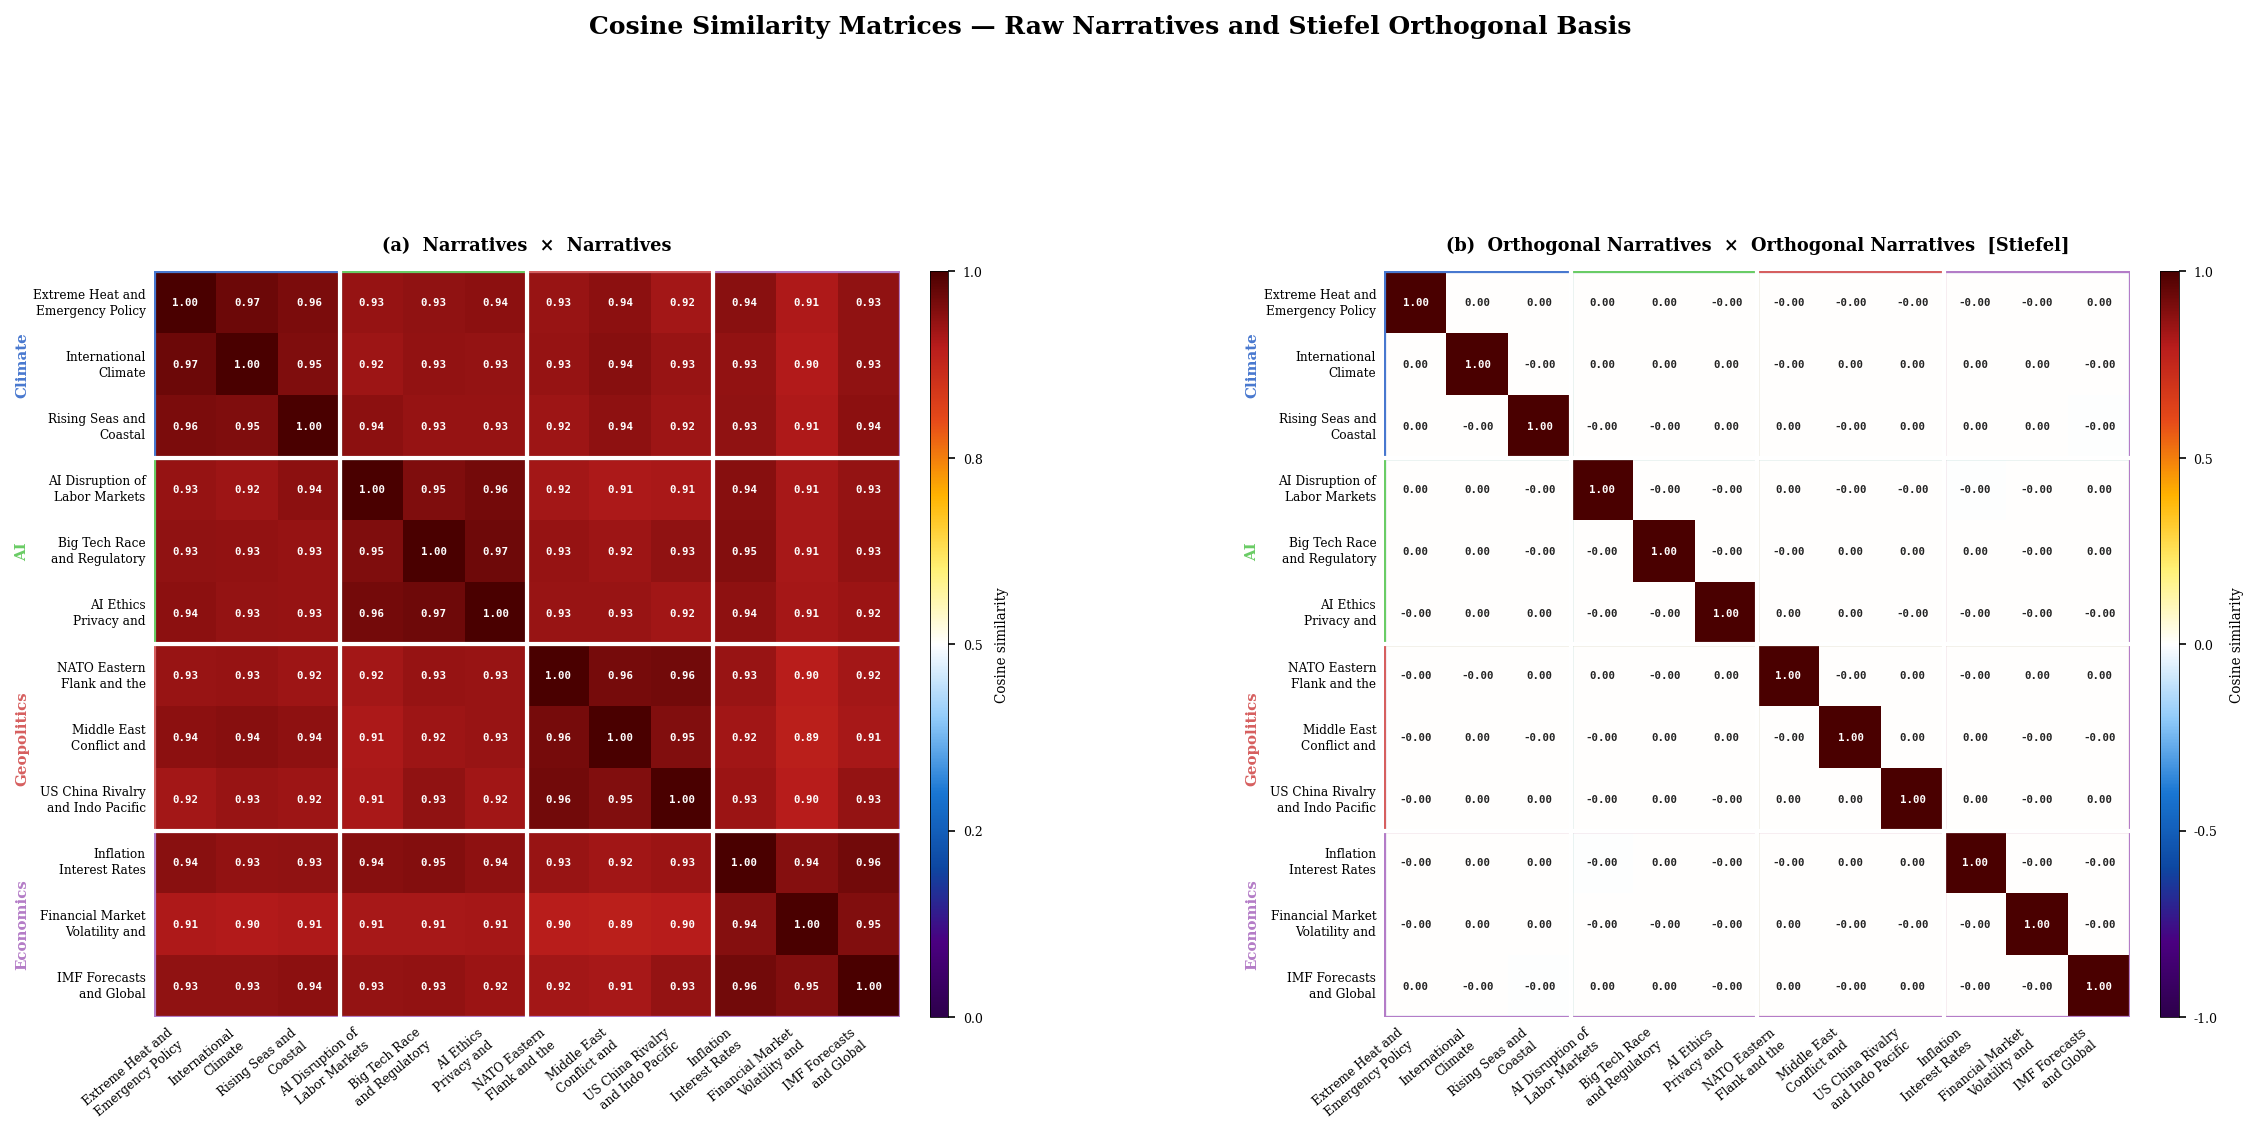

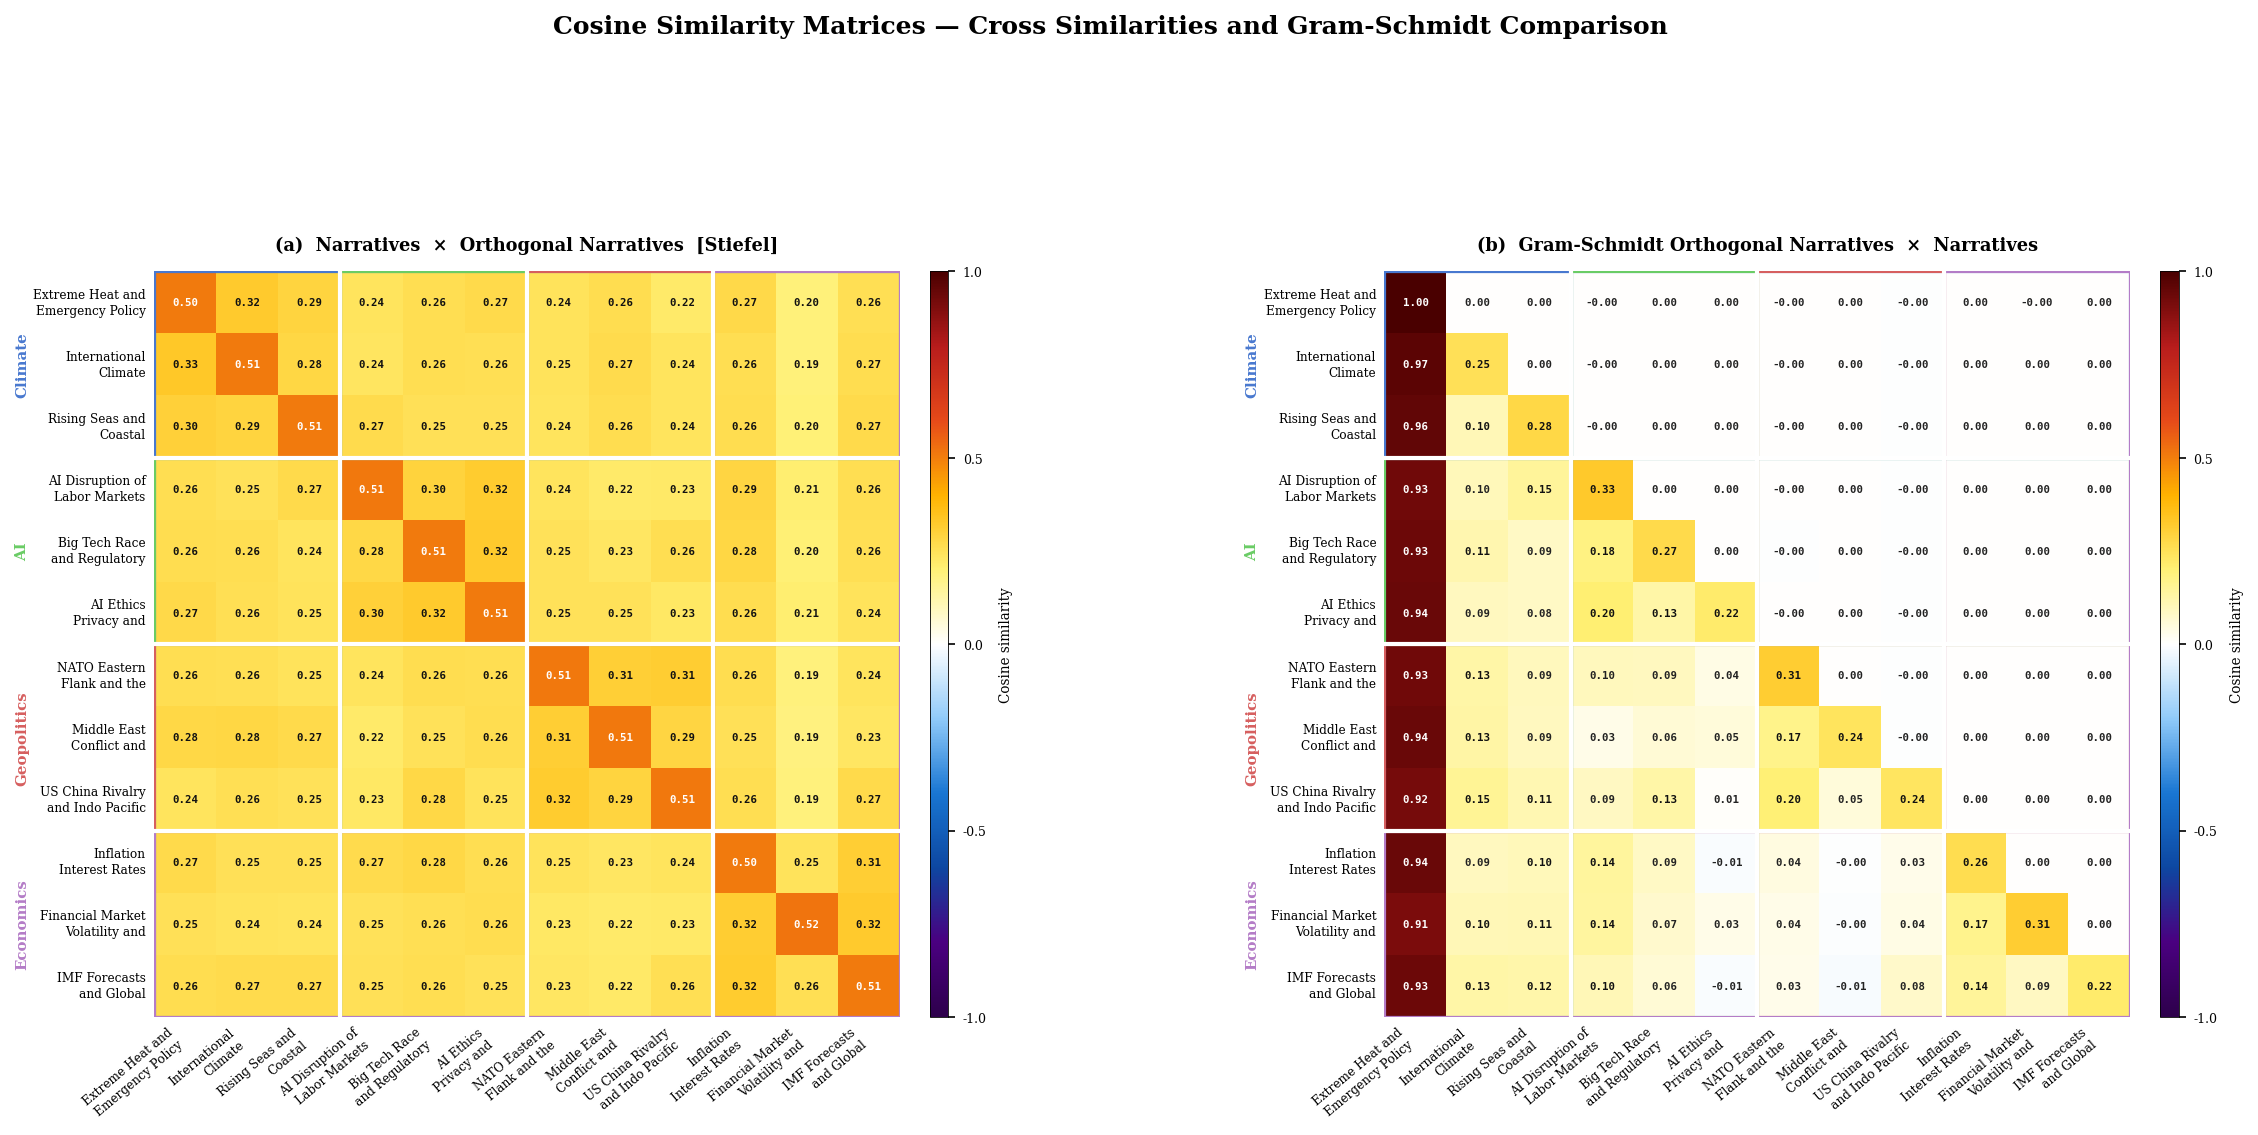

✓  Two figures saved as PDF and PNG.


In [28]:

# ── 0.  Global aesthetic settings ─────────────────────────────────────────────
plt.rcParams.update({
    "font.family":        "serif",
    "font.serif":         ["Times New Roman", "DejaVu Serif"],
    "axes.spines.top":    False,
    "axes.spines.right":  False,
    "axes.spines.left":   False,
    "axes.spines.bottom": False,
    "figure.dpi":         150,
    "savefig.dpi":        300,
})

CMAP = LinearSegmentedColormap.from_list(
    "spectral_contrast",
    [
        "#2d004b",
        "#4a0080",
        "#0d47a1",
        "#1976d2",
        "#90caf9",
        "#ffffff",
        "#fff176",
        "#ffb300",
        "#e64a19",
        "#b71c1c",
        "#4a0000",
    ],
    N=512
)

CHAPTER_PAL = {
    "climate":                 "#4878CF",
    "artificial_intelligence": "#6ACC65",
    "geopolitics":             "#D65F5F",
    "economics":               "#B47CC7",
}

_ABBREV = {
    "climate":                 "Climate",
    "artificial_intelligence": "AI",
    "geopolitics":             "Geopolitics",
    "economics":               "Economics",
}

# ── 1.  Labels ─────────────────────────────────────────────────────────────────
#chapters      = [row["chapter"] for row in rows]
#titles_raw    = [row["title"]   for row in rows]
chapters =  [1 for row in rows]
titles_raw = [title for narratives in narratives_by_chapter2.values() for title in narratives.keys()]
chapter_names = list(narratives_by_chapter2.keys())
chapter_size  = 3
n             = len(rows)   # 12

def short(title, maxw=16):
    words = title.replace("_", " ").split()
    lines, cur = [], []
    for w in words:
        if sum(len(x) + 1 for x in cur) + len(w) > maxw:
            lines.append(" ".join(cur))
            cur = [w]
        else:
            cur.append(w)
    if cur:
        lines.append(" ".join(cur))
    return "\n".join(lines[:2])

tick_labels = [short(t) for t in titles_raw]

# ── 2.  Similarity matrices ────────────────────────────────────────────────────
sim_NN    = cosine_similarity(narrative_matrix2,  narrative_matrix2)
sim_N_ON  = cosine_similarity(narrative_matrix2,  orthogonal_matrix2)
sim_ON_ON = cosine_similarity(orthogonal_matrix2, orthogonal_matrix2)
sim_GS    = cosine_similarity(gram_schmidt(narrative_matrix2), narrative_matrix2)

# ── 3.  Core drawing function ──────────────────────────────────────────────────
def draw_heatmap(ax, matrix, row_labels, col_labels, title,
                 vmin=-1, vmax=1, annot=True):

    nr, nc = matrix.shape

    # Background chapter shading
    for i, ch in enumerate(chapter_names):
        c = CHAPTER_PAL[ch]
        ax.add_patch(mpatches.Rectangle(
            (-0.5, i * chapter_size - 0.5), nc, chapter_size,
            color=c, alpha=0.08, linewidth=0, zorder=0
        ))
        ax.add_patch(mpatches.Rectangle(
            (i * chapter_size - 0.5, -0.5), chapter_size, nr,
            color=c, alpha=0.08, linewidth=0, zorder=0
        ))

    # Normalisation
    if vmin == 0:
        display_matrix = matrix * 2 - 1
    else:
        display_matrix = matrix
    norm = TwoSlopeNorm(vmin=-1, vcenter=0.0, vmax=1)

    # ── KEY CHANGE: aspect="equal" forces square cells ────────────────────────
    im = ax.imshow(display_matrix, cmap=CMAP, norm=norm,
                   aspect="equal", interpolation="none", zorder=1)

    # Chapter block borders
    for i, ch in enumerate(chapter_names):
        c = CHAPTER_PAL[ch]
        s = i * chapter_size
        ax.add_patch(mpatches.Rectangle(
            (-0.5, s - 0.5), nc, chapter_size,
            edgecolor=c, facecolor="none",
            linewidth=1.5, zorder=3, alpha=1.0
        ))
        ax.add_patch(mpatches.Rectangle(
            (s - 0.5, -0.5), chapter_size, nr,
            edgecolor=c, facecolor="none",
            linewidth=1.5, zorder=3, alpha=1.0
        ))

    # White separators
    for k in range(1, n // chapter_size):
        pos = k * chapter_size - 0.5
        ax.axvline(pos, color="white", lw=2.0, zorder=4)
        ax.axhline(pos, color="white", lw=2.0, zorder=4)

    # Cell annotations
    if annot:
        for i in range(nr):
            for j in range(nc):
                v = matrix[i, j]
                if v < -0.20:
                    fg = "white"
                elif v < 0.10:
                    fg = "#222222"
                elif v < 0.38:
                    fg = "#111111"
                else:
                    fg = "white"
                ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                        fontsize=5.2, color=fg, fontfamily="monospace",
                        fontweight="bold", zorder=5)

    # Tick labels
    ax.set_xticks(range(nc))
    ax.set_xticklabels(col_labels, fontsize=5.8, rotation=40,
                       ha="right", va="top", linespacing=1.3)
    ax.set_yticks(range(nr))
    ax.set_yticklabels(row_labels, fontsize=5.8, va="center",
                       linespacing=1.3)
    ax.tick_params(length=0, pad=4)

    # Chapter labels — y-axis only
    for i, ch in enumerate(chapter_names):
        mid  = i * chapter_size + (chapter_size - 1) / 2
        col  = CHAPTER_PAL[ch]
        name = _ABBREV[ch]
        ax.annotate(
            name,
            xy=(-0.5, mid), xycoords="data",
            xytext=(-60, 0), textcoords="offset points",
            ha="right", va="center",
            fontsize=7.2, fontweight="bold", color=col,
            annotation_clip=False,
            rotation=90
        )

    # Centred title
    ax.set_title(title, fontsize=8.5, fontweight="bold",
                 pad=10, loc="center")

    ax.set_xlim(-0.5, nc - 0.5)
    ax.set_ylim(nr - 0.5, -0.5)

    return im


def add_colorbar(fig, im, ax, vmin, vmax):
    cbar_ax = ax.inset_axes([1.04, 0.0, 0.025, 1.0])
    ticks   = np.linspace(vmin, vmax, 5)
    cb = fig.colorbar(im, cax=cbar_ax, ticks=np.linspace(-1, 1, 5))
    cb.ax.set_yticklabels([f"{v:.1f}" for v in ticks], fontsize=6)
    cb.set_label("Cosine similarity", fontsize=6.5, labelpad=6)
    cb.outline.set_linewidth(0.4)


# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 1  —  (a) N × N   |   (b) ON × ON  [Stiefel]
# ══════════════════════════════════════════════════════════════════════════════
fig1, axes1 = plt.subplots(
    1, 2,
    figsize=(17, 8),
    gridspec_kw={"wspace": 0.65}
)

panels_fig1 = [
    (axes1[0], sim_NN,    tick_labels, tick_labels,
     "(a)  Narratives  ×  Narratives",
     0,  1),
    (axes1[1], sim_ON_ON, tick_labels, tick_labels,
     "(b)  Orthogonal Narratives  ×  Orthogonal Narratives  [Stiefel]",
     -1, 1),
]

for ax, mat, rl, cl, title, vmin, vmax in panels_fig1:
    im = draw_heatmap(ax, mat, rl, cl, title, vmin=vmin, vmax=vmax)
    add_colorbar(fig1, im, ax, vmin, vmax)

fig1.suptitle(
    "Cosine Similarity Matrices — Raw Narratives and Stiefel Orthogonal Basis",
    fontsize=12, fontweight="bold", y=1.02
)
fig1.savefig("fig1_N_and_ON.pdf", bbox_inches="tight")
fig1.savefig("fig1_N_and_ON.png", bbox_inches="tight", dpi=300)


# ══════════════════════════════════════════════════════════════════════════════
# FIGURE 2  —  (a) N × ON  [Stiefel]   |   (b) GS-ON × N  [Gram-Schmidt]
# ══════════════════════════════════════════════════════════════════════════════
fig2, axes2 = plt.subplots(
    1, 2,
    figsize=(17, 8),
    gridspec_kw={"wspace": 0.65}
)

panels_fig2 = [
    (axes2[0], sim_N_ON,  tick_labels, tick_labels,
     "(a)  Narratives  ×  Orthogonal Narratives  [Stiefel]",
     -1, 1),
    (axes2[1], sim_GS.T,  tick_labels, tick_labels,
     "(b)  Gram-Schmidt Orthogonal Narratives  ×  Narratives",
     -1, 1),
]

for ax, mat, rl, cl, title, vmin, vmax in panels_fig2:
    im = draw_heatmap(ax, mat, rl, cl, title, vmin=vmin, vmax=vmax)
    add_colorbar(fig2, im, ax, vmin, vmax)

fig2.suptitle(
    "Cosine Similarity Matrices — Cross Similarities and Gram-Schmidt Comparison",
    fontsize=12, fontweight="bold", y=1.02
)
fig2.savefig("fig2_cross_and_GS.pdf", bbox_inches="tight")
fig2.savefig("fig2_cross_and_GS.png", bbox_inches="tight", dpi=300)

plt.show()
print("✓  Two figures saved as PDF and PNG.")

This is just an example as we are not using those narratives for our main experiments

# IV Main computations: cosine similarities with $N_i$, $V_i$

Here we are:

1. Computing the embeddings of all articles in our news dataset, and then obtaining a collection $(X_n)_n$ of article embeddings;
2. Computing the cosine similarities of :

    a) Article embeddings with raw narratives $N_i$: $cos(N_i, X_n)$

    b) Article embeddings with orthogonalized narratives $V_i$: $cos(V_i, X_n)$

In [29]:
"""Create dataframe with the cosine similarity with orthogonal narratives"""
from tqdm.notebook import tqdm
from sklearn.metrics.pairwise import cosine_similarity

print("Computing cosine similarities with narratives and orthogonal narratives...")


time_series_data = []
gdir = './data_narratives'

for idx, row in tqdm(data.iterrows(), total=len(data)):
    # Get article embedding
    article_embedding = row['embedding']
    if isinstance(article_embedding, list):
        article_embedding = np.array(article_embedding)
    
    info_similarities = {
        'date': row['date'],
        'category': row['category'],
        'headline': row['headline'],
        'link': row.get('link', '')
    }
    
    # Compute cosine similarities with narratives (vectorized)
    similarities_narratives = cosine_similarity(
        article_embedding.reshape(1, -1),
        narrative_matrix
    )[0]
    
    for name, sim in zip(narrative_names, similarities_narratives):
        info_similarities[f"{name}"] = float(sim)
    
    # Compute cosine similarities with orthogonal narratives (vectorized)
    similarities_orthogonal = cosine_similarity(
        article_embedding.reshape(1, -1),
        orthogonal_matrix
    )[0]

    for name, sim in zip(orthogonal_names, similarities_orthogonal):
        info_similarities[f"{name}"] = float(sim)


    time_series_data.append(info_similarities)

# Save to CSV
ts_df = pd.DataFrame(time_series_data)
filepath = os.path.join(gdir, 'narrative_exposures_with_orthogonal.csv')
os.makedirs(gdir, exist_ok=True)
ts_df.to_csv(filepath, index=False)
print(f"✓ Saved to: {filepath}")
print(f"Shape: {ts_df.shape}")
print(f"Columns: {ts_df.columns.tolist()[:10]}...")  # Show first 10 columns

Computing cosine similarities with narratives and orthogonal narratives...


  0%|          | 0/67361 [00:00<?, ?it/s]

✓ Saved to: ./data_narratives/narrative_exposures_with_orthogonal.csv
Shape: (67361, 28)
Columns: ['date', 'category', 'headline', 'link', 'politics:Trump_as_Disruptor_and_Institutional_Stress', 'politics:Culture_War_and_Identity_Conflict', 'politics:Welfare_State_Under_Press', 'entertainment:Entertainment_as_Political_Resistance', 'entertainment:Franchise_Nostalgia_and_Serial_Dominance', 'entertainment:Celebrity_Image_Management_in_the_Social_Media_Age']...


# V Visualization

**V.1 All new, all narratives**

1) Narratives $N_i$

In [30]:
""" Prepare data for visualization """
ts_df['date_dt'] = pd.to_datetime(ts_df['date'])

# Extract narrative columns (those with ':' in the name)
all_cols = [col for col in ts_df.columns if ':' in col]

# Separate narratives and orthogonal narratives
narrative_cols = [col for col in all_cols if '_orth' not in col and '_comple' not in col]
orthogonal_cols = [col for col in all_cols if '_orth' in col]
residuals_cols = [col for col in all_cols if '_comple' in col]
print(len(narrative_cols))

# Get unique news categories
news_categories = sorted(ts_df['category'].unique()) 


12


In [31]:
ts_df["date_dt"] = pd.to_datetime(ts_df["date"])

all_cols = [col for col in ts_df.columns if ":" in col]
narrative_cols = [col for col in all_cols if "_orth" not in col and "_comple" not in col]
orthogonal_cols = [col for col in all_cols if "_orth" in col]
residuals_cols = [col for col in all_cols if "_comple" in col]

# tous les chapitres présents dans les narratifs (pas de filtrage)
all_chapters = sorted(set(col.split(":")[0] for col in narrative_cols))
print(f"Chapters found : {all_chapters}")

Chapters found : ['entertainment', 'parenting', 'politics', 'travel']


In [32]:
from adjustText import adjust_text

def plot_narrative_timeseries(
    cols, chapters, ts_df,
    span_weeks=4, strip_suffix="",
    title="", start="2014-01-01", end="2018-12-31",
    events=None, figsize=(16, 8), save = False, file_title="narrative_timeseries.pdf"
):
    ts_df_period = ts_df[(ts_df["date_dt"] >= start) & (ts_df["date_dt"] <= end)].copy()
    fig, ax = plt.subplots(figsize=figsize)

    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

    palette = plt.cm.tab20(np.linspace(0, 1, max(10, len(cols))))

    n = 0
    for chapter in chapters:
        for col in [c for c in cols if c.startswith(f"{chapter}:")]:
            weekly_mean = (
                ts_df_period.groupby(pd.Grouper(key="date_dt", freq="W-MON"))[col].mean()
            )
            smoothed = weekly_mean.ewm(span=span_weeks, adjust=False).mean()

            narrative_name = col.split(":")[1].replace(strip_suffix, "").replace("_", " ")
            ax.plot(smoothed.index, smoothed.values,
                    label=f"{chapter.capitalize()} - {narrative_name}",
                    color=palette[n % len(palette)], linewidth=2.2)
            n += 1

    if events is not None:
        event_texts = []
        for i, (date_str, label) in enumerate(sorted(events.items())):
            x = pd.Timestamp(date_str)
            ax.axvline(x=x, color="red", linestyle="--", linewidth=1.4, alpha=0.9)

            # fixed top band, vertical text
            text_obj = ax.text(
                x, ax.get_ylim()[1] * 0.96, label,
                rotation=90, fontsize=8, color="red",
                fontweight="bold",
                ha="center", va="bottom",
                bbox=dict(
                    boxstyle="round,pad=0.18",
                    facecolor="white",
                    edgecolor="red",
                    alpha=0.8,
                    linewidth=0.8
                )
            )
            event_texts.append(text_obj)

        adjust_text(
            event_texts,
            ax=ax,
            only_move={"points": "y", "text": "y"},
            arrowprops=dict(arrowstyle="-", color="gray", lw=0.5)
        )

    ax.set_title(title, fontsize=16, fontweight="bold")
    ax.set_xlabel("Date", fontsize=12)
    ax.set_ylabel("Weekly Mean $\\hat{p}$ (EMA)", fontsize=12)
    ax.grid(True, alpha=0.25, linestyle="--", linewidth=0.6)
    ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False, fontsize=8)

    if save:
        plt.savefig(file_title, bbox_inches="tight")

    plt.tight_layout()
    plt.show()

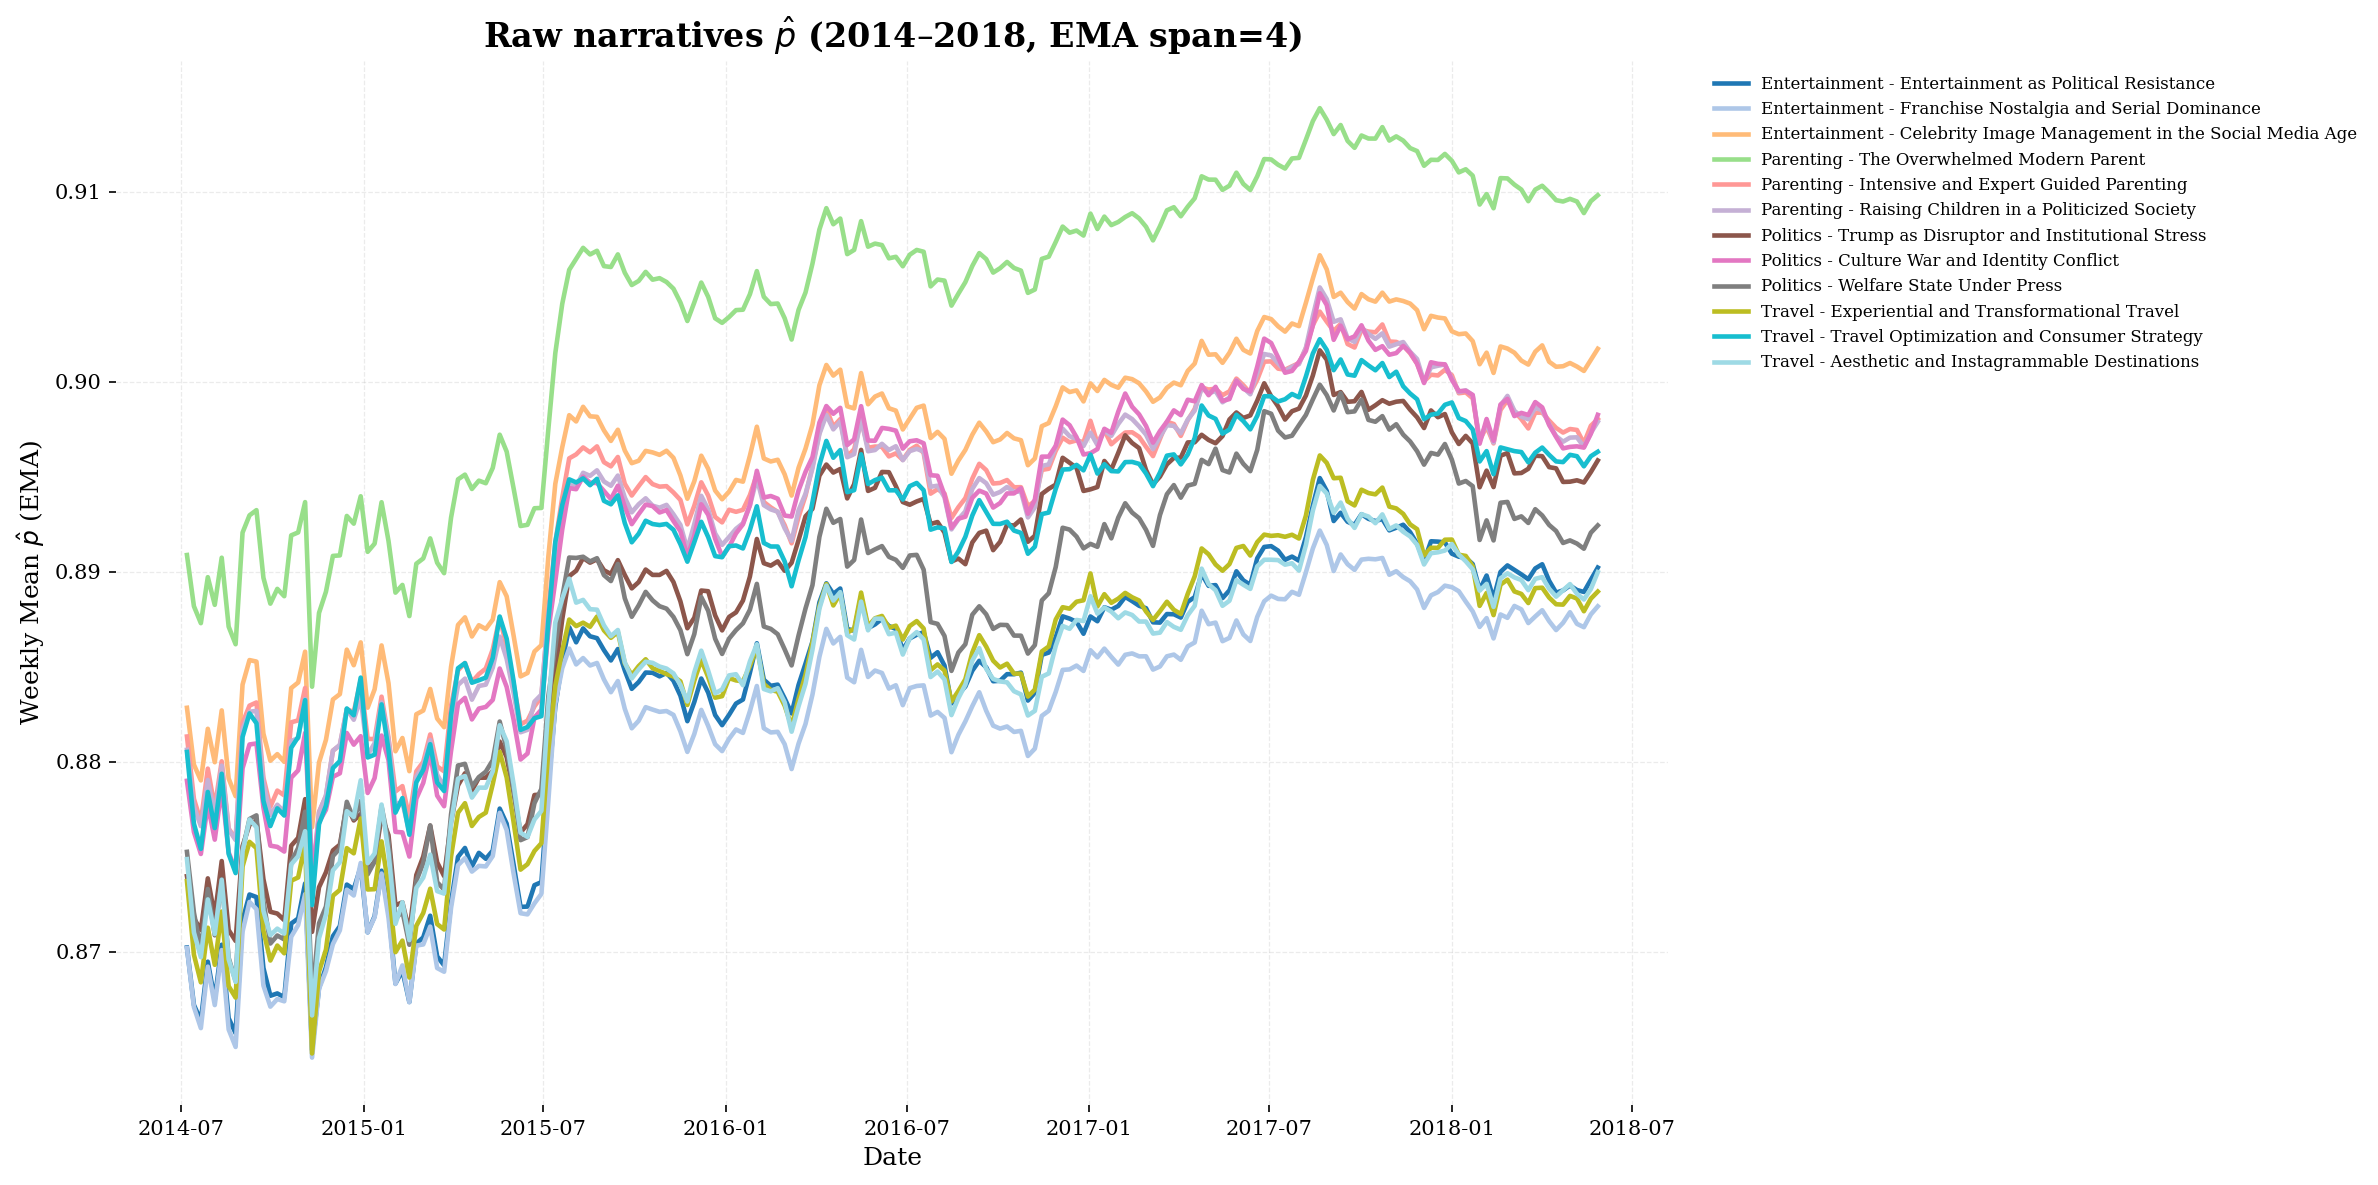

In [33]:
""" Raw narratives, all chapters, EMA span=4 weeks, 2014–2018 """
plot_narrative_timeseries(
    narrative_cols, all_chapters, ts_df,
    title="Raw narratives $\\hat{p}$ (2014–2018, EMA span=4)",
    start="2014-07-01", end="2018-07-31"
)

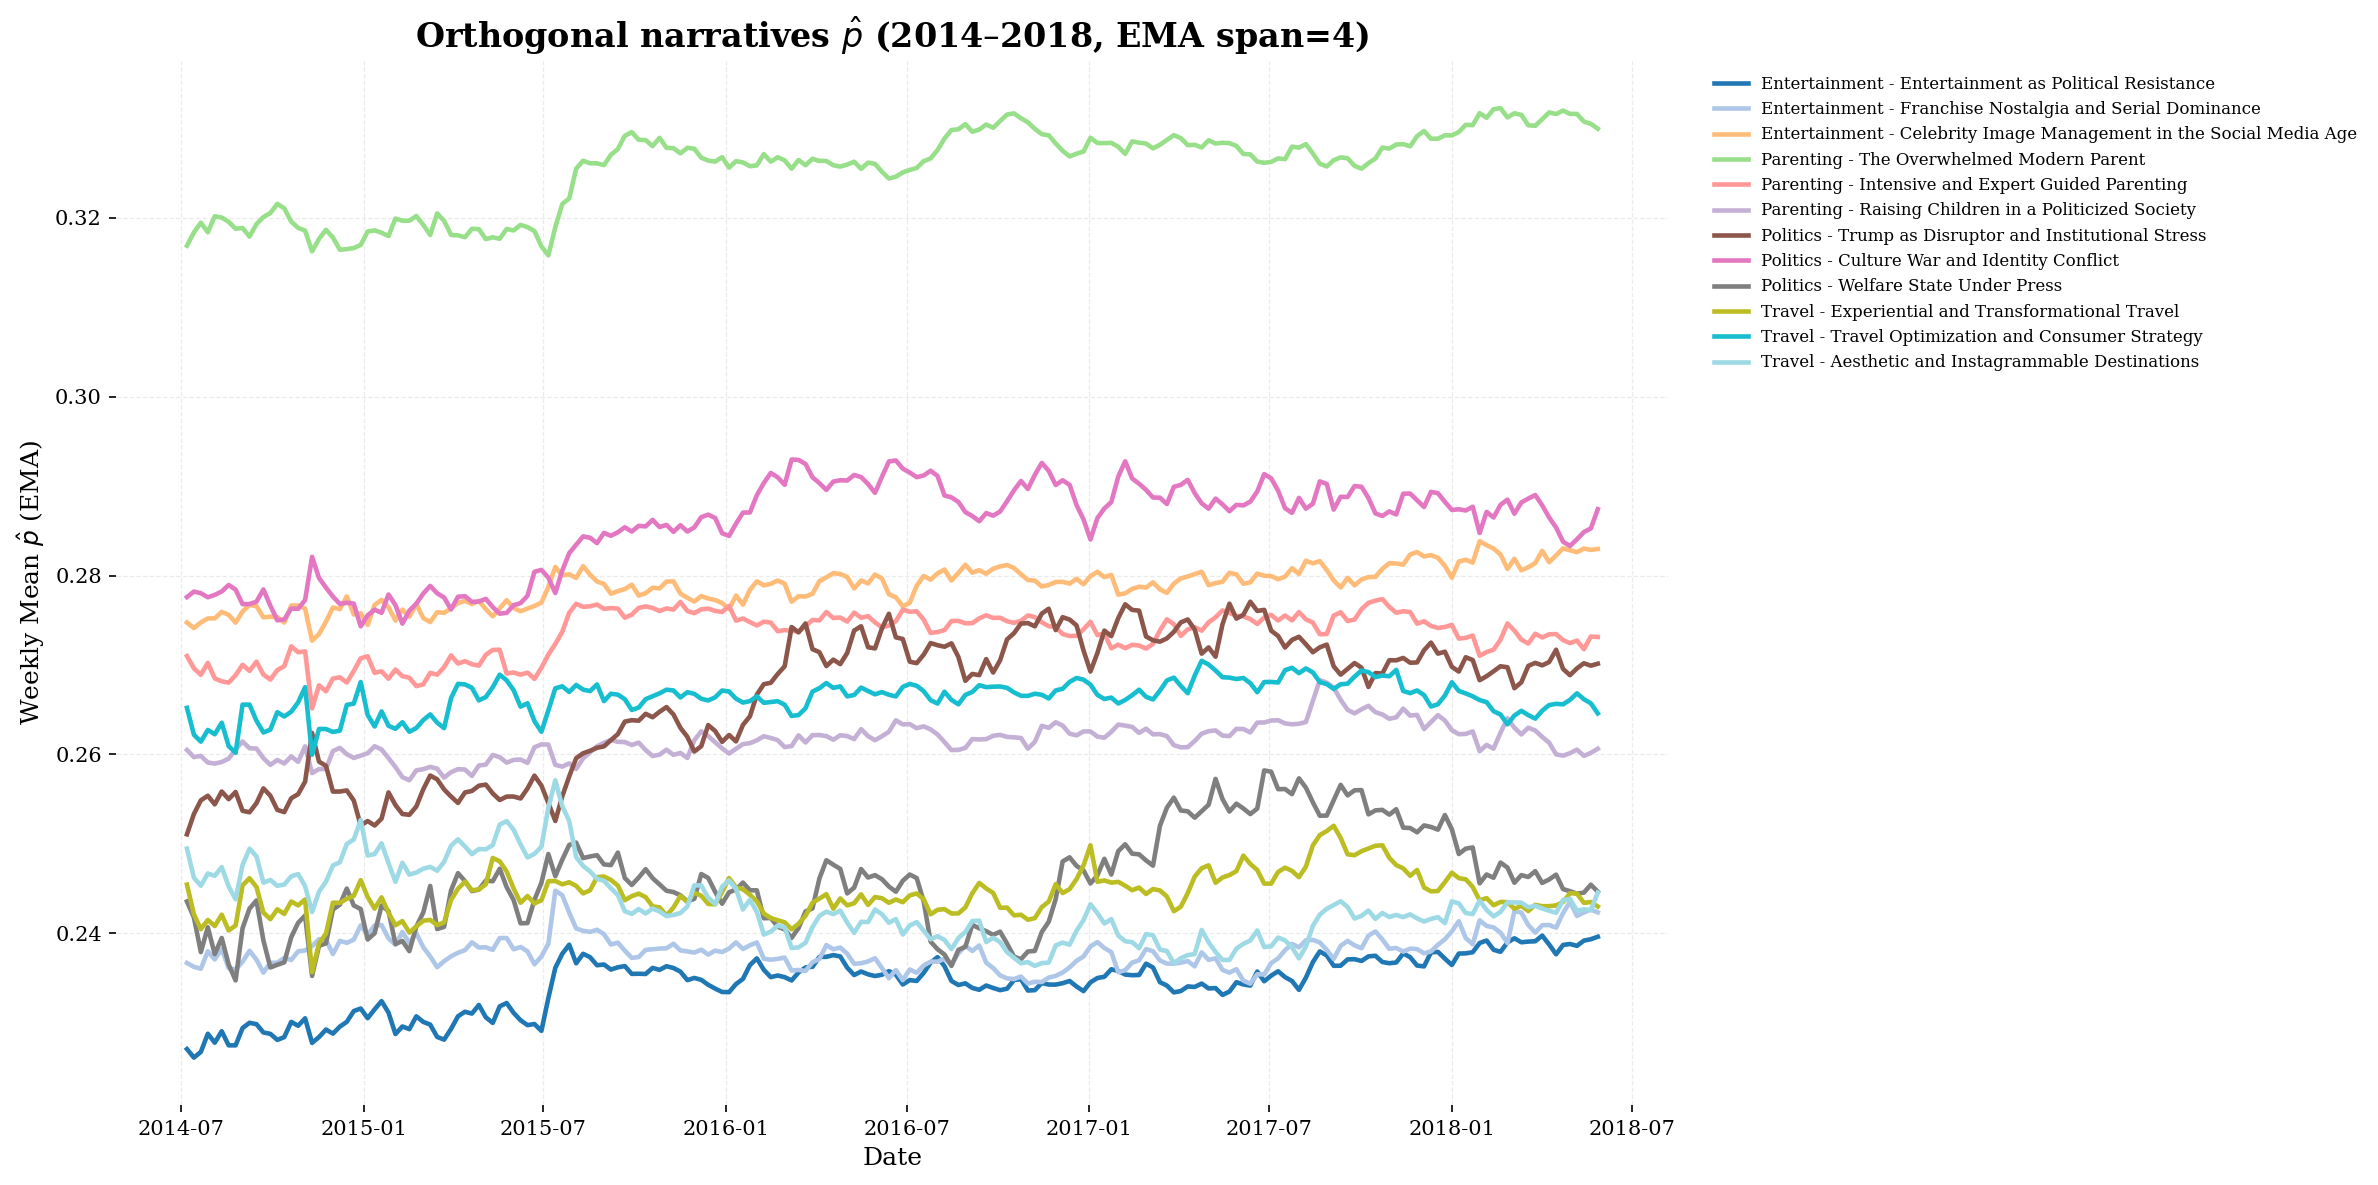

In [34]:
""" Orthogonal narratives, all chapters, EMA span=4 weeks, 2014–2018 """
plot_narrative_timeseries(
    orthogonal_cols, all_chapters, ts_df,
    strip_suffix="_orth",
    title="Orthogonal narratives $\\hat{p}$ (2014–2018, EMA span=4)",
    start="2014-07-01", end="2018-07-31"
)

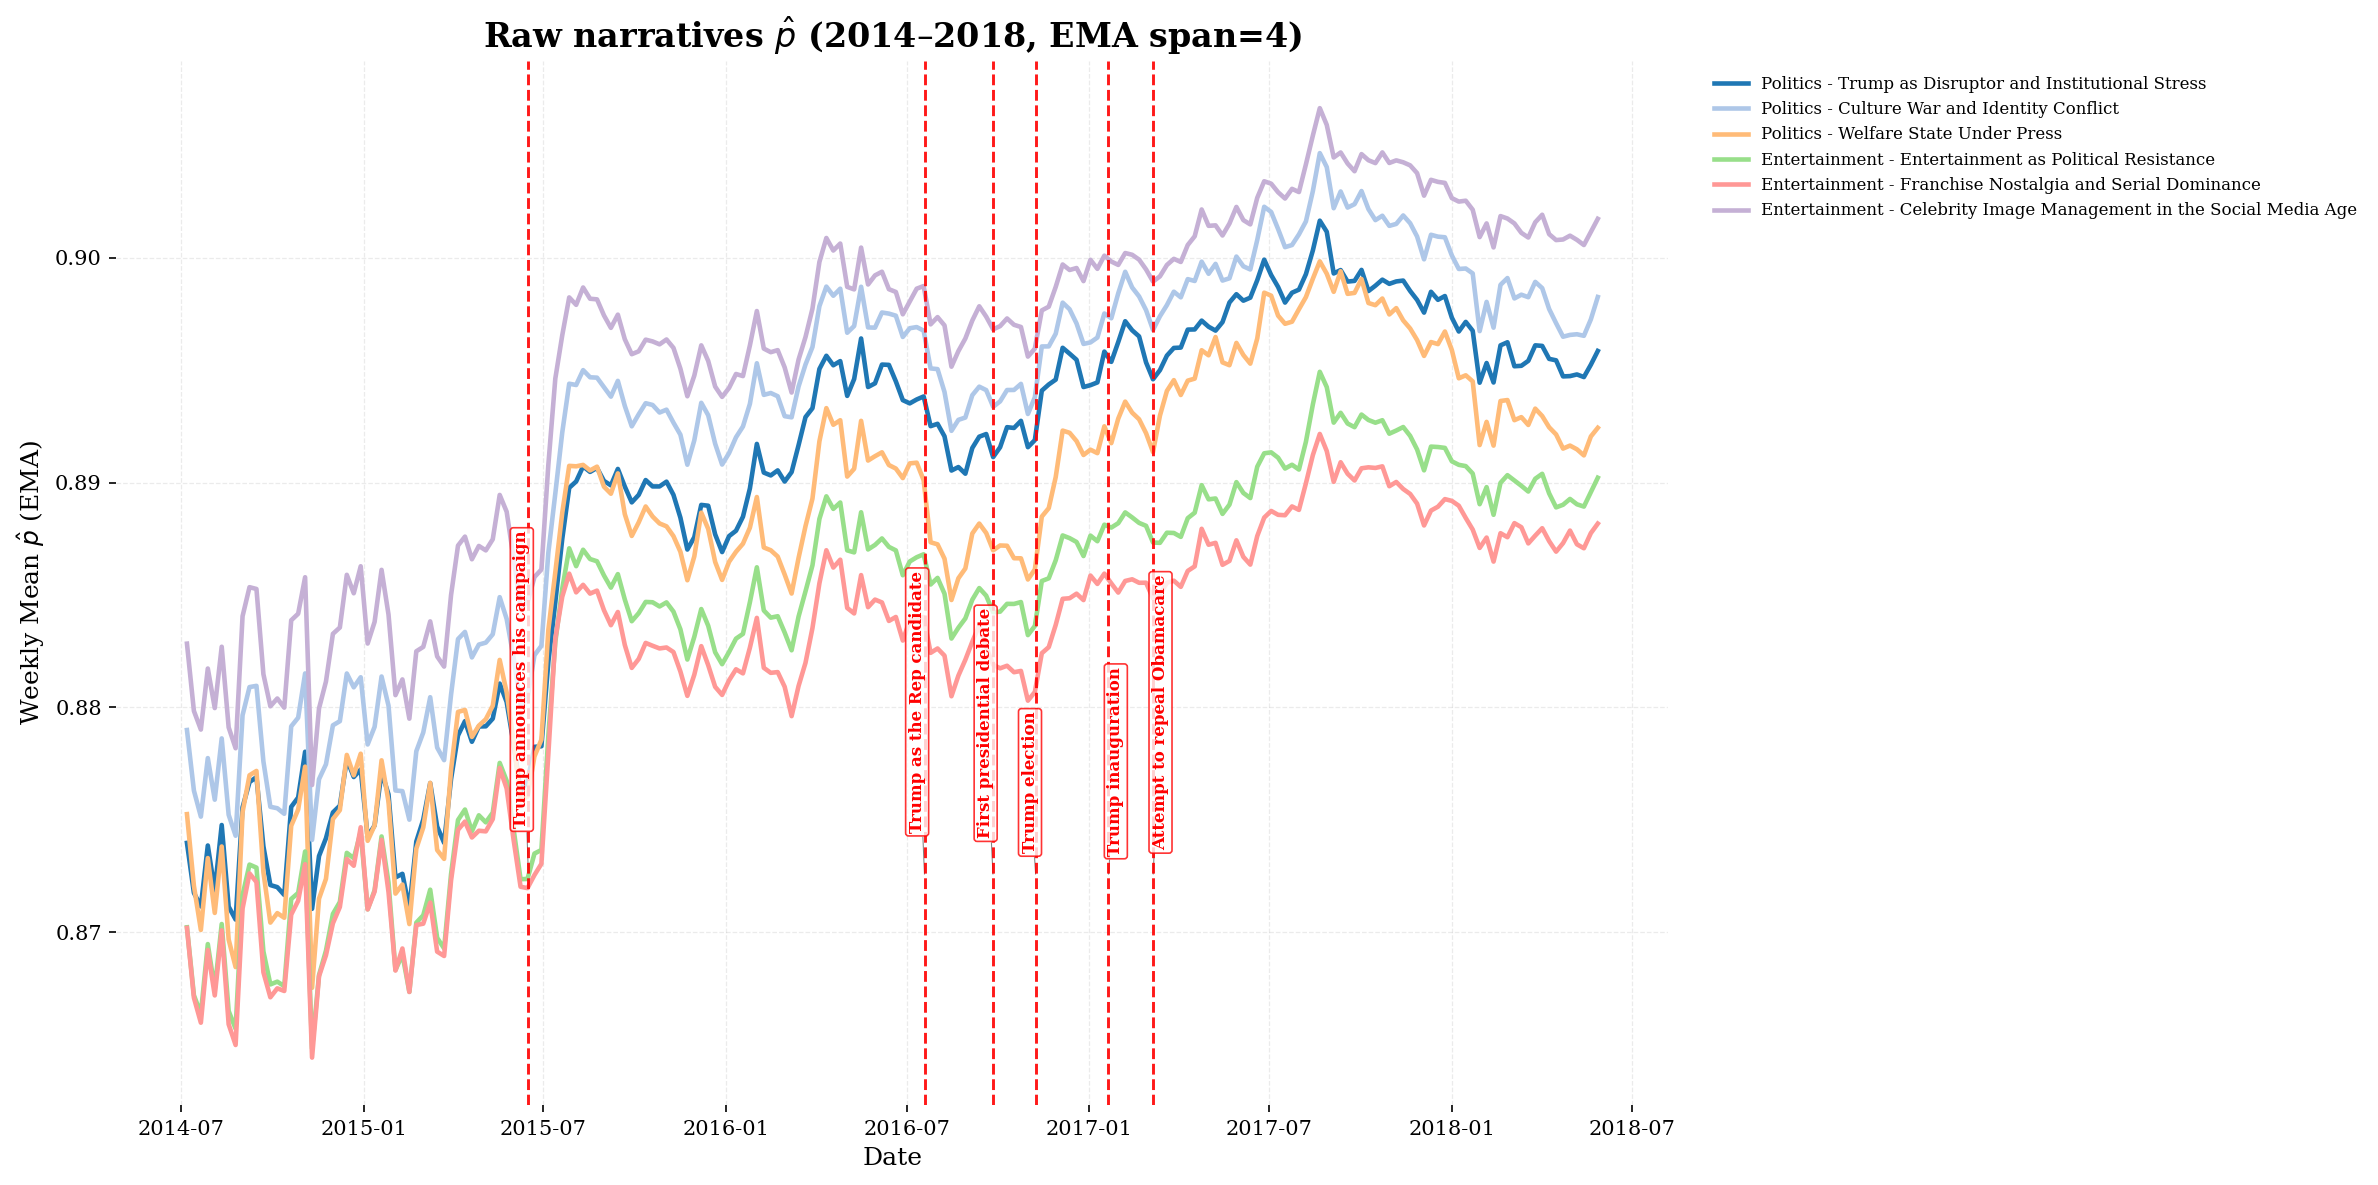

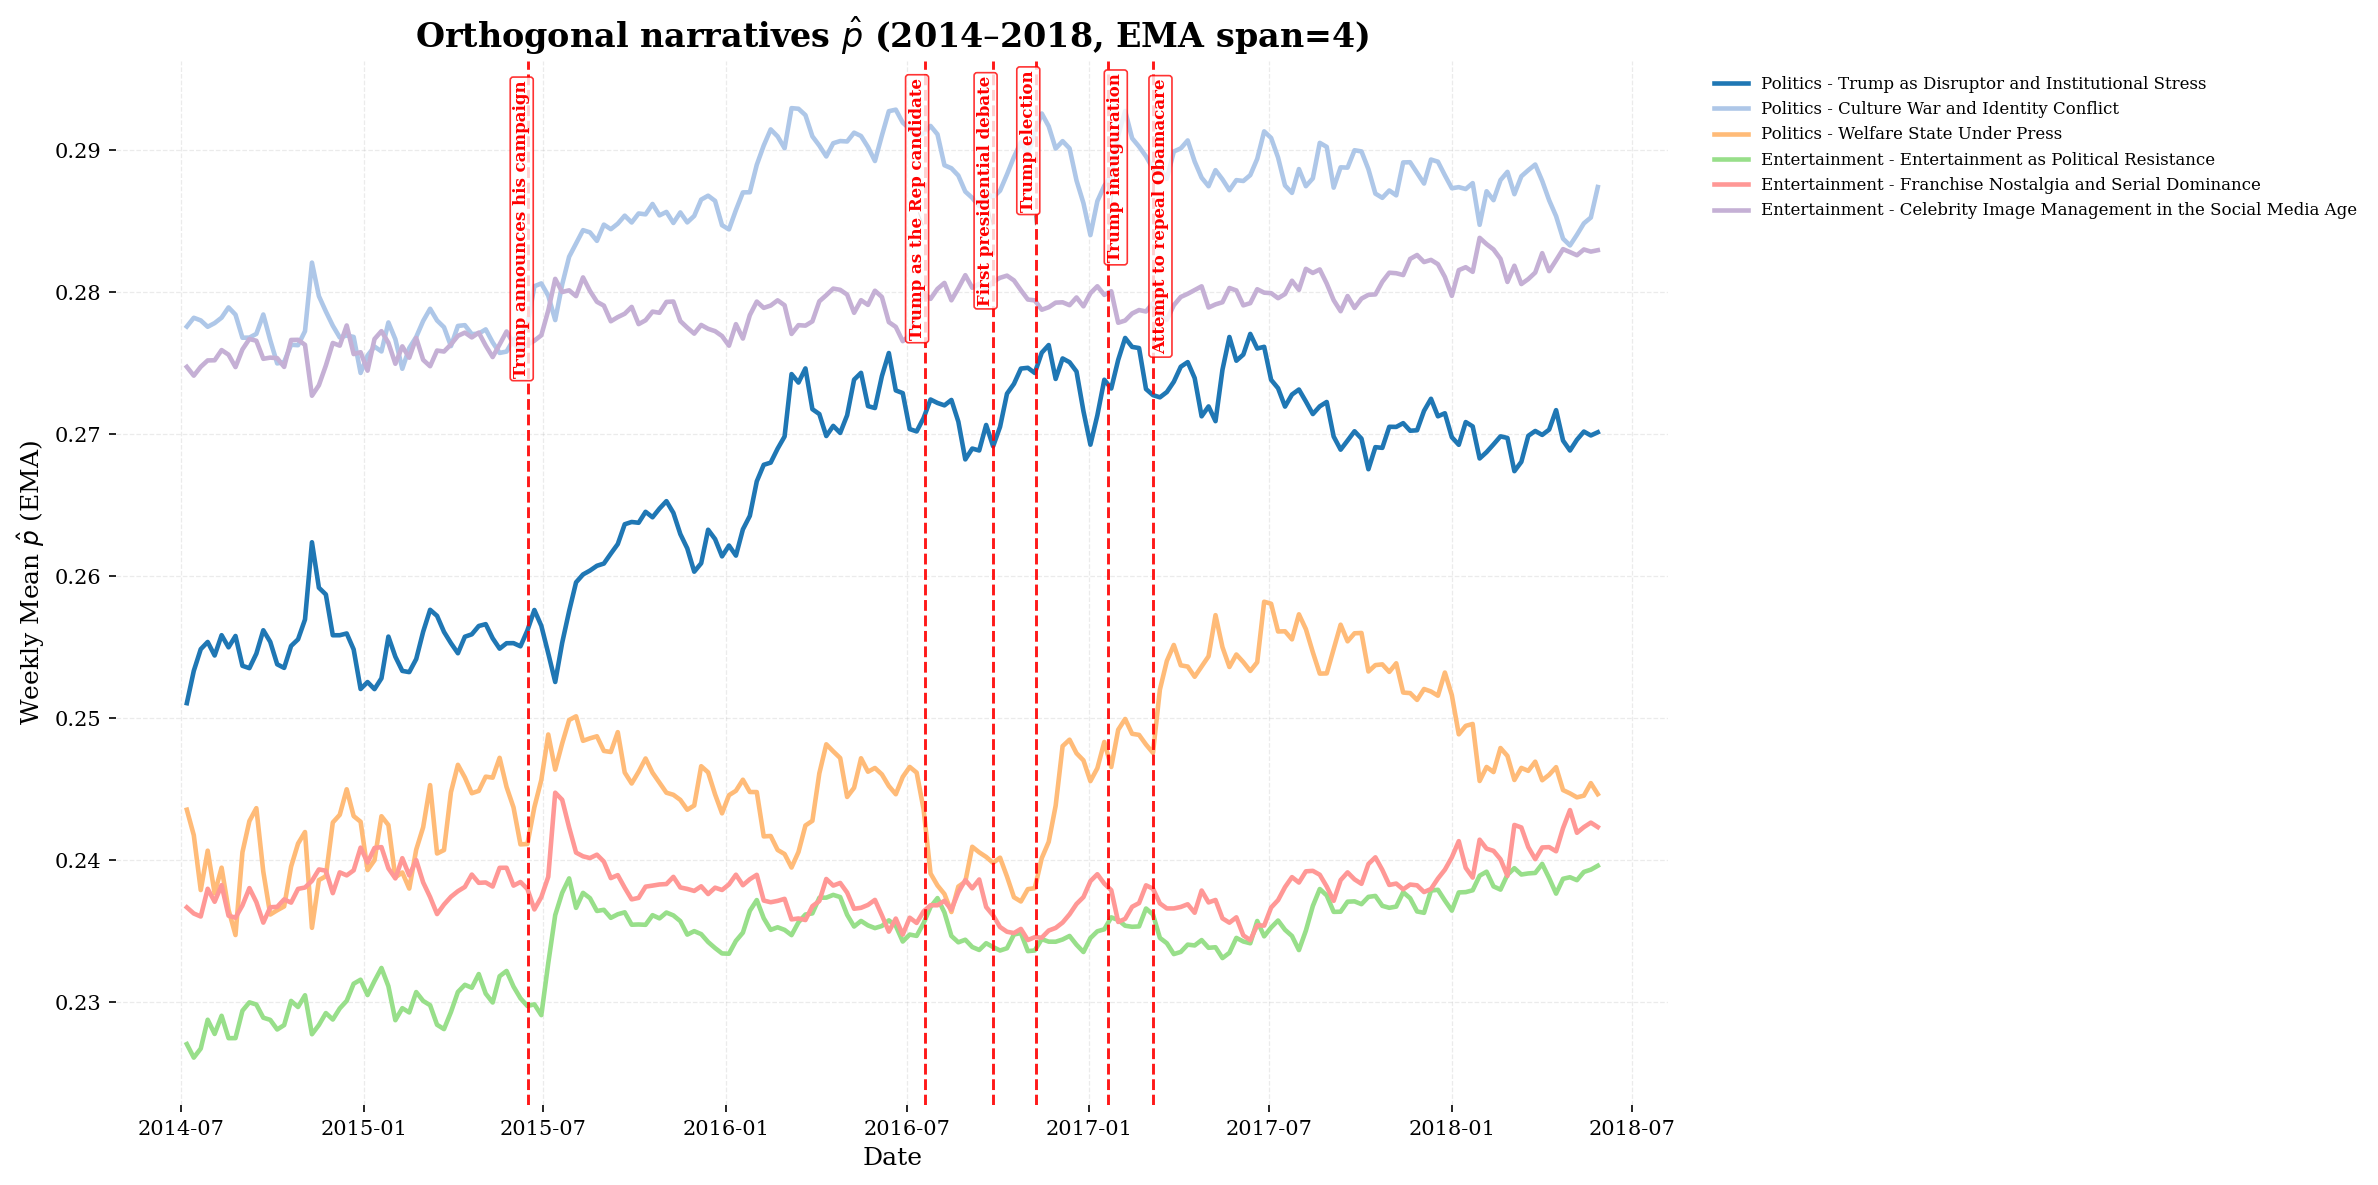

In [35]:
selected_chapters = ["politics", "entertainment"]

events = {
    "2015-06-16": "Trump announces his campaign",
    "2016-07-19": "Trump as the Rep candidate",
    "2016-09-26": "First presidential debate",
    "2016-11-08": "Trump election",
    "2017-01-20": "Trump inauguration",
    "2017-03-06": "Attempt to repeal Obamacare",
}

""" Raw narratives, selected chapters, EMA span=4 weeks, 2014–2018 """
plot_narrative_timeseries(
    narrative_cols, selected_chapters, ts_df,
    title="Raw narratives $\\hat{p}$ (2014–2018, EMA span=4)",
    start="2014-07-01", end="2018-07-31", events=events, save = True, file_title="raw_narratives_selected_chapters.pdf"
)

""" Orthogonal narratives, selected chapters, EMA span=4 weeks, 2014–2018 """
plot_narrative_timeseries(
    orthogonal_cols, selected_chapters, ts_df,
    strip_suffix="_orth",
    title="Orthogonal narratives $\\hat{p}$ (2014–2018, EMA span=4)",
    start="2014-07-01", end="2018-07-31", events=events, save= True, file_title="pure_narratives_selected_chapters.pdf"
)

# VI. Tables

**VI.1 Table 1: pairwise narrative covariation before and after orthogonalization**

In [36]:
# ============================================================
# Pairwise co-movement of narratives, weekly:
#   M_hat_ij(t) = (1/n_t) * sum_{n in C_t} (X_n^T W_i)(X_n^T W_j)
#   M_N[i,j] = mean_t M_hat_ij(t)   (raw narratives N)
#   M_V[i,j] = mean_t M_hat_ij(t)   (orthogonalized narratives V)
# ============================================================
import numpy as np
import pandas as pd

ts = ts_df.copy()
ts["date_dt"] = pd.to_datetime(ts["date"])

# ------------------------------------------------------------
# 1) Find matched N / V narrative columns
# ------------------------------------------------------------
all_cols = [c for c in ts.columns if ":" in c]
cols_N_raw = [c for c in all_cols if "_orth" not in c and "_comple" not in c]

col_N_to_V = {}
for col_n in cols_N_raw:
    chapter, name = col_n.split(":", 1)
    col_v = f"{chapter}:{name}_orth"
    if col_v in ts.columns:
        col_N_to_V[col_n] = col_v

cols_N = sorted(col_N_to_V.keys(), key=lambda c: (c.split(":", 1)[0], c.split(":", 1)[1]))
cols_V = [col_N_to_V[c] for c in cols_N]

if len(cols_N) == 0:
    raise ValueError("No matched N / V narrative pairs were found in ts_df.")

base_labels = cols_N.copy()

ts[cols_N] = ts[cols_N].apply(pd.to_numeric, errors="coerce")
ts[cols_V] = ts[cols_V].apply(pd.to_numeric, errors="coerce")
ts = ts.dropna(subset=cols_N + cols_V + ["date_dt"])   # remove rows with NaN in any of the relevant columns

# ------------------------------------------------------------
# 2) Weekly estimator M_hat(t)
# ------------------------------------------------------------
weekly = ts.groupby(pd.Grouper(key="date_dt", freq="W-MON"))

def weekly_M_hat(cols):
    mats = []
    for _, g in weekly:
        if len(g) == 0:          
            continue
        B = g[cols].to_numpy(dtype=float)       # (n_t, K) : B[n,i] = X_n^T W_i
        mats.append((B.T @ B) / B.shape[0])     # (1/n_t) sum_n B[n,i] B[n,j]
    if len(mats) == 0:
        raise ValueError("No weekly observations found after aggregation.")
    return np.stack(mats)                        # (T, K, K)

M_N_t = weekly_M_hat(cols_N)
M_V_t = weekly_M_hat(cols_V)

# ------------------------------------------------------------
# 3) Average over time to get M_N and M_V
# ------------------------------------------------------------
M_N = pd.DataFrame(M_N_t.mean(axis=0), index=base_labels, columns=base_labels)
M_V = pd.DataFrame(M_V_t.mean(axis=0), index=base_labels, columns=base_labels)

# ------------------------------------------------------------
# Scale
# ------------------------------------------------------------
scale = 1.0          # mettre p.ex. 1e-3 si M_V est de l'ordre de 1e-3
M_N_disp = M_N / scale
M_V_disp = M_V / scale

# ------------------------------------------------------------
# 5) Descriptive statistics table + LaTeX export
# ------------------------------------------------------------
def upper_triangle_values(df):
    mask = np.triu(np.ones(df.shape, dtype=bool), k=1)
    return df.where(mask).stack().values

offdiag_N = upper_triangle_values(M_N_disp)
offdiag_V = upper_triangle_values(M_V_disp)

stats_table = pd.DataFrame(
    {
        "N (raw)": [
            np.mean(offdiag_N), np.std(offdiag_N), np.median(offdiag_N),
            np.min(offdiag_N), np.max(offdiag_N),
        ],
        "V (purified)": [
            np.mean(offdiag_V), np.std(offdiag_V), np.median(offdiag_V),
            np.min(offdiag_V), np.max(offdiag_V),
        ],
    },
    index=["mean", "std", "median", "min", "max"],
).round(3)

display(Markdown(r"### Descriptive statistics — pairwise narrative co-movement $M_{ij}$"))
display(stats_table)


def df_to_latex_booktabs(df, caption, label, float_fmt="%.3f"):
    n_cols = len(df.columns)
    col_format = "l" + "c" * n_cols
    lines = [
        r"\begin{table}[t]",
        r"\centering",
        rf"\begin{{tabular}}{{{col_format}}}",
        r"\toprule",
        " & ".join([""] + list(df.columns)) + r" \\",
        r"\midrule",
    ]
    for idx, row in df.iterrows():
        values = " & ".join(float_fmt % v for v in row.values)
        lines.append(f"{idx} & {values} \\\\")
    lines += [
        r"\bottomrule",
        r"\end{tabular}",
        rf"\caption{{{caption}}}",
        rf"\label{{{label}}}",
        r"\end{table}",
    ]
    return "\n".join(lines)


latex_code = df_to_latex_booktabs(
    stats_table,
    caption=r"Descriptive statistics of pairwise narrative co-movement $M_{ij}$, before (N) and after (V) orthogonalization.",
    label="tab:covariation_stats",
)
print(latex_code)

### Descriptive statistics — pairwise narrative co-movement $M_{ij}$

,N (raw),V (purified)
mean,0.809,0.071
std,0.007,0.008
median,0.808,0.070
min,0.795,0.057
max,0.825,0.091


\begin{table}[t]
\centering
\begin{tabular}{lcc}
\toprule
 & N (raw) & V (purified) \\
\midrule
mean & 0.809 & 0.071 \\
std & 0.007 & 0.008 \\
median & 0.808 & 0.070 \\
min & 0.795 & 0.057 \\
max & 0.825 & 0.091 \\
\bottomrule
\end{tabular}
\caption{Descriptive statistics of pairwise narrative co-movement $M_{ij}$, before (N) and after (V) orthogonalization.}
\label{tab:covariation_stats}
\end{table}


**VI.2 Table 2: to assess semantic specificity**

In [37]:
def delta(df, chapter, narrative_name):
    average_cosine_N_in_chapter = df[df['category'].str.lower() == chapter][f"{chapter}:{narrative_name}"].mean()
    average_cosine_V_in_chapter = df[df['category'].str.lower() == chapter][f"{chapter}:{narrative_name}_orth"].mean()
    average_cosine_N_out_chapter = df[df['category'].str.lower() != chapter][f"{chapter}:{narrative_name}"].mean()
    average_cosine_V_out_chapter = df[df['category'].str.lower() != chapter ][f"{chapter}:{narrative_name}_orth"].mean()
    delta_N = average_cosine_N_in_chapter - average_cosine_N_out_chapter
    delta_V = average_cosine_V_in_chapter - average_cosine_V_out_chapter
    return delta_N, delta_V

def bootstrap_delta_ci(df, chapter, narrative_name, n_bootstrap=100, frac=0.2, alpha=0.05):
    rng = np.random.default_rng(42)

  
    chapter_df = df[df["category"].str.lower() == chapter].copy()
    out_df = df[df["category"].str.lower() != chapter].copy()

    n_in = len(chapter_df)
    n_out = len(out_df)
    m_in = max(1, int(n_in * frac))
    m_out = max(1, int(n_out * frac))

    Delta_N = np.empty(n_bootstrap, dtype=float)
    Delta_V = np.empty(n_bootstrap, dtype=float)
    Gain = np.empty(n_bootstrap, dtype=float)

    for b in range(n_bootstrap):
        in_idx = rng.choice(np.arange(n_in), size=m_in, replace=True)
        out_idx = rng.choice(np.arange(n_out), size=m_out, replace=True)

        sample_in = chapter_df.iloc[in_idx]
        sample_out = out_df.iloc[out_idx]

        avg_N_in = sample_in[f"{chapter}:{narrative_name}"].mean()
        avg_V_in = sample_in[f"{chapter}:{narrative_name}_orth"].mean()
        avg_N_out = sample_out[f"{chapter}:{narrative_name}"].mean()
        avg_V_out = sample_out[f"{chapter}:{narrative_name}_orth"].mean()

        delta_N = avg_N_in - avg_N_out
        delta_V = avg_V_in - avg_V_out

        Delta_N[b] = delta_N
        Delta_V[b] = delta_V
        Gain[b] = delta_V - delta_N

    return {
        "mean_delta_N": Delta_N.mean(),
        "mean_delta_V": Delta_V.mean(),
        "mean_gain": Gain.mean(),
        "ci_delta_N_low": np.quantile(Delta_N, alpha/2),
        "ci_delta_N_high": np.quantile(Delta_N, 1 - alpha/2),
        "ci_delta_V_low": np.quantile(Delta_V, alpha/2),
        "ci_delta_V_high": np.quantile(Delta_V, 1 - alpha/2),
        "ci_gain_low": np.quantile(Gain, alpha/2),
        "ci_gain_high": np.quantile(Gain, 1 - alpha/2),
    }


boot_rows = []
n_boot = 1000
frac = 1
for chapter in narratives_by_chapter.keys():
    for narrative in narratives_by_chapter[chapter].keys():
        stats_boot = bootstrap_delta_ci(ts_df, chapter, narrative, n_bootstrap=n_boot, frac=frac, alpha=0.05)
        boot_rows.append({"chapter": chapter, "narrative": narrative, **stats_boot})

df_boot = pd.DataFrame(boot_rows)






In [38]:
# ------------------------------------------------------------
# Paper-ready display: mean [CI lo, CI hi], significance flagged
# ------------------------------------------------------------
def fmt_ci(mean, lo, hi, sig=None):
    star = "$^{*}$" if sig else ""
    return f"{mean:.4f}{star} [{lo:.4f}, {hi:.4f}]"

display_rows = []
for _, row in df_boot.iterrows():
    display_rows.append({
        "Chapter": "Right" if "droite" in row["chapter"] else "Left" if "gauche" in row["chapter"] else row["chapter"],
        "Narrative": row["narrative"].replace("_", " ").capitalize(),
        r"$\Delta^i(N_i)$": fmt_ci(row["mean_delta_N"], row["ci_delta_N_low"], row["ci_delta_N_high"]),
        r"$\Delta^i(V_i)$": fmt_ci(row["mean_delta_V"], row["ci_delta_V_low"], row["ci_delta_V_high"]),
        r"$\Delta_{\text{gain}}$": fmt_ci(row["mean_gain"], row["ci_gain_low"], row["ci_gain_high"]),
    })

boot_display = pd.DataFrame(display_rows)

display(Markdown(f"### Sensitivity analysis — {n_boot} bootstrap draws, {int(frac*100)}% of articles, 95% CI"))
display(boot_display)

### Sensitivity analysis — 1000 bootstrap draws, 100% of articles, 95% CI

,Chapter,Narrative,$\Delta^i(N_i)$,$\Delta^i(V_i)$,$\Delta_{\text{gain}}$
0,politics,Trump as disruptor and institutional stress,"0.0045 [0.0042, 0.0050]","0.0381 [0.0378, 0.0385]","0.0336 [0.0331, 0.0340]"
1,politics,Culture war and identity conflict,"0.0025 [0.0021, 0.0029]","0.0311 [0.0308, 0.0314]","0.0287 [0.0282, 0.0291]"
2,politics,Welfare state under press,"-0.0021 [-0.0025, -0.0016]","0.0111 [0.0106, 0.0116]","0.0132 [0.0129, 0.0135]"
3,entertainment,Entertainment as political resistance,"-0.0126 [-0.0131, -0.0120]","0.0062 [0.0059, 0.0066]","0.0188 [0.0184, 0.0191]"
4,entertainment,Franchise nostalgia and serial dominance,"-0.0084 [-0.0089, -0.0079]","0.0212 [0.0208, 0.0217]","0.0296 [0.0291, 0.0300]"
5,entertainment,Celebrity image management in the social media...,"-0.0130 [-0.0135, -0.0125]","0.0071 [0.0067, 0.0074]","0.0201 [0.0196, 0.0205]"
6,parenting,The overwhelmed modern parent,"0.0254 [0.0251, 0.0258]","0.0107 [0.0102, 0.0111]","-0.0147 [-0.0152, -0.0143]"
7,parenting,Intensive and expert guided parenting,"0.0291 [0.0287, 0.0295]","0.0301 [0.0295, 0.0308]","0.0011 [0.0005, 0.0016]"
8,parenting,Raising children in a politicized society,"0.0244 [0.0241, 0.0248]","0.0169 [0.0165, 0.0173]","-0.0075 [-0.0079, -0.0072]"
9,travel,Experiential and transformational travel,"0.0255 [0.0249, 0.0260]","0.0301 [0.0296, 0.0308]","0.0047 [0.0042, 0.0052]"


**VI.3 Rupture test**

In [39]:

TRUMP_CAMPAIGN_EVENTS = [
    ("2015-06-16", "Campaign announcement",
     "Trump officially announces his candidacy for the Republican presidential nomination from Trump Tower in New York City."),

    ("2015-08-06", "First Republican debate",
     "First televised Republican primary debate hosted by Fox News; Trump engages in a widely publicized exchange with journalist Megyn Kelly."),

    ("2015-12-07", "Proposal to ban Muslim entry",
     "Trump calls for a total suspension of Muslims entering the United States, triggering nationwide controversy."),

    ("2016-02-01", "Iowa caucus defeat",
     "Trump finishes second behind Ted Cruz in the first contest of the Republican primaries."),

    ("2016-03-15", "Super Tuesday II and Marco Rubio's withdrawal",
     "Trump wins several primaries, including Florida; Marco Rubio suspends his campaign after losing in his home state."),

    ("2016-05-04", "Ted Cruz and John Kasich withdraw",
     "Following Trump's victory in Indiana on May 3, Ted Cruz suspends his campaign, followed by John Kasich the next day; Trump becomes the only active Republican candidate."),

    ("2016-05-26", "Delegate threshold reached",
     "The Associated Press announces that Trump has secured enough delegates to guarantee his nomination as the Republican presidential candidate."),

    ("2016-08-01", "Controversy over Humayun Khan's parents",
     "Trump's remarks targeting the parents of Captain Humayun Khan, a Muslim American soldier killed in Iraq, trigger strong political and media reactions."),

    ("2016-09-26", "First presidential debate",
     "First televised debate between Donald Trump and Hillary Clinton, covering issues including the economy, national security, and the candidates' policy positions."),

    ("2016-10-07", "Release of the Access Hollywood recording",
     "The release of a 2005 recording reveals Trump's vulgar remarks about women and triggers a major political and media crisis."),

    ("2016-10-28", "James Comey's letter to Congress",
     "FBI Director James Comey informs Congress that the FBI is examining additional emails potentially related to the investigation into Hillary Clinton's email practices, reigniting controversy days before the election."),

    ("2016-11-08", "Election Day",
     "Donald Trump wins the 2016 United States presidential election, defeating Democratic nominee Hillary Clinton."),

    ("2017-01-20", "Inauguration",
     "Donald Trump is inaugurated as the 45th President of the United States in a ceremony held at the United States Capitol.")
]

In [40]:
import numpy as np
import pandas as pd
from scipy import stats
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Markdown

# Article embeddings already available in the notebook
embeddings = [np.asarray(e, dtype=float) for e in data_with_embeddings["embedding"]]
dates = pd.to_datetime(data_with_embeddings["date"])

narrative_labels = [f"{r['chapter']}:{r['title']}" for r in narrative_rows]  # même ordre que narrative_matrix / orthogonal_matrix

def get_narrative_vectors(label):
    idx = narrative_labels.index(label)
    return narrative_matrix[idx], orthogonal_matrix[idx]

t_begin = pd.Timestamp("2014-07-01")
t_end = pd.Timestamp("2018-07-31")

In [41]:
# ------------------------------------------------------------
# 1) Moving-window two-sided Welch tests (V, N, V-N) + FDR (BH)
# ------------------------------------------------------------

diff_col_map = {"p_delta_V": "diff_V", "p_delta_N": "diff_N", "p_diff": "diff_diff"}

def run_moving_tests_fdr(
    embeddings: list, dates, N: np.ndarray, V: np.ndarray,
    t_begin: pd.Timestamp, t_end: pd.Timestamp,
    window_size: int = 1, bandwidth_days: int = 90,
) -> pd.DataFrame:
    """
    For each day t in [t_begin, t_end], runs three two-sided Welch t-tests
    (equal_var=False) comparing the `bandwidth_days` after t to the `bandwidth_days`
    before t (articles within +-window_size days of t are excluded):
        p_delta_V : mean(X·V) shifted around t
        p_delta_N : mean(X·N) shifted around t
        p_diff    : shift in V differs from shift in N
    Direction is recovered from diff_V / diff_N / diff_diff. BH-FDR-corrected
    versions of each p-value are added as `<col>_fdr`.
    """
    dates_s = pd.Series(pd.to_datetime(dates)).reset_index(drop=True)
    scores_V = np.array([x @ V for x in embeddings], dtype=float)
    scores_N = np.array([x @ N for x in embeddings], dtype=float)
    scores = {"p_delta_V": scores_V, "p_delta_N": scores_N, "p_diff": scores_V - scores_N}

    window, bandwidth = pd.Timedelta(days=window_size), pd.Timedelta(days=bandwidth_days)
    rows = []
    for t in pd.date_range(start=t_begin, end=t_end, freq="D"):
        before = ((dates_s >= t - bandwidth - window) & (dates_s < t - window)).to_numpy()
        after = ((dates_s > t + window) & (dates_s <= t + bandwidth + window)).to_numpy()
        if min(before.sum(), after.sum()) < 2:
            continue
        p_vals, diffs = {}, {}
        for p_col, s in scores.items():
            p_vals[p_col] = stats.ttest_ind(s[after], s[before], alternative="two-sided", equal_var=False)[1]
            diffs[diff_col_map[p_col]] = s[after].mean() - s[before].mean()
        rows.append({"date": t, **p_vals, **diffs})

    df = pd.DataFrame(rows)
    for col in scores:
        df[f"{col}_fdr"] = multipletests(df[col], method="fdr_bh")[1]
    return df


# ------------------------------------------------------------
# 2) Rupture detection: trim edges, group consecutive significant days
# ------------------------------------------------------------

def detect_ruptures(results: pd.DataFrame, test_col: str = "p_delta_V", alpha: float = 0.05, trim_days: int = 90):
    fdr_col, diff_col = f"{test_col}_fdr", diff_col_map[test_col]
    df = results.copy().sort_values("date").reset_index(drop=True)

    # Drop results too close to the edges (structurally the least reliable)
    t_min, t_max = df["date"].min(), df["date"].max()
    df = df[(df["date"] >= t_min + pd.Timedelta(days=trim_days)) &
            (df["date"] <= t_max - pd.Timedelta(days=trim_days))].reset_index(drop=True)

    df["significant"] = df[fdr_col] < alpha
    df["group"] = (df["significant"] != df["significant"].shift()).cumsum()

    events = []
    for _, g in df[df["significant"]].groupby("group"):
        best = g.loc[g[test_col].idxmin()]
        events.append({
            "rupture_date": best["date"],
            "run_start": g["date"].min(),
            "run_end": g["date"].max(),
            "p_raw": best[test_col],
            "p_fdr": best[fdr_col],
            "direction": "+" if best[diff_col] > 0 else "-",
            "magnitude": best[diff_col],
            "n_consecutive_days": len(g),
        })
    cols = ["rupture_date", "run_start", "run_end", "p_raw", "p_fdr", "direction", "magnitude", "n_consecutive_days"]
    return df, pd.DataFrame(events, columns=cols).sort_values("rupture_date").reset_index(drop=True)


# ------------------------------------------------------------
# 3) Shared helper: weekly mean of article scores, EMA-smoothed
# ------------------------------------------------------------

def weekly_ema(scores, dates, start, end, span_weeks=4):
    s = pd.Series(scores, index=pd.to_datetime(dates)).groupby(pd.Grouper(freq="W-MON")).mean()
    return s[(s.index >= start) & (s.index <= end)].ewm(span=span_weeks, adjust=False).mean()


In [42]:
def _draw_narrative_on_ax(
    ax, embeddings, dates, label, t_begin, t_end,
    color_N="steelblue", color_V="firebrick",
    bandwidth_days=90, alpha=0.05, trim_days=90, span_weeks=4,
    start=None, end=None,
    bar_linewidth=8, bar_alpha=0.45,
    y_top=1.10, y_bottom=-0.14,
    events=None,
):
    # By default, the displayed period = the tested period
    start = t_begin if start is None else start
    end = t_end if end is None else end

    N, V = get_narrative_vectors(label)

    results = run_moving_tests_fdr(embeddings, dates, N, V, t_begin, t_end, bandwidth_days=bandwidth_days)
    _, ruptures_N = detect_ruptures(results, test_col="p_delta_N", alpha=alpha, trim_days=trim_days)
    _, ruptures_V = detect_ruptures(results, test_col="p_delta_V", alpha=alpha, trim_days=trim_days)

    s_N = weekly_ema(np.array([x @ N for x in embeddings], dtype=float), dates, start, end, span_weeks)
    s_V = weekly_ema(np.array([x @ V for x in embeddings], dtype=float), dates, start, end, span_weeks)
    s_V_rescaled = (s_V - s_V.min()) / (s_V.max() - s_V.min()) * (s_N.max() - s_N.min()) + s_N.min()

    ax.plot(s_N.index, s_N.values, color=color_N, linewidth=1.5, linestyle="-", label="N")
    ax.plot(s_V_rescaled.index, s_V_rescaled.values, color=color_V, linewidth=1.5, linestyle="-",
            label="V (rééchelonné)")

    # Rupture bars: x in data coordinates, y in axes fraction (above/below the plot area)
    trans = ax.get_xaxis_transform()
    for ruptures, color, y in [(ruptures_N, color_N, y_top), (ruptures_V, color_V, y_bottom)]:
        for _, row in ruptures.iterrows():
            ax.plot([row["run_start"], row["run_end"]], [y, y],
                    color=color, linewidth=bar_linewidth, alpha=bar_alpha,
                    solid_capstyle="butt", transform=trans, clip_on=False)

    # Optional exogenous event lines, no labels
    if events is not None:
        for date_str, _, _ in events:
            date = pd.to_datetime(date_str)
            if date < start or date > end:
                continue
            ax.axvline(date, color="gray", linestyle="--", linewidth=1.0, alpha=0.8)

    return ruptures_N, ruptures_V



In [43]:
def plot_narratives_ruptures(
    embeddings, dates, labels, t_begin, t_end,
    color_N="steelblue", color_V="firebrick",
    bandwidth_days=90, alpha=0.05, trim_days=90, span_weeks=4,
    start=None, end=None, events=None,
    panel_h=5.5,            # slot height per panel, in inches
    suptitle_block_in=1.0,  # room for suptitle + legend, in inches
    footer_in=0.9,          # room below the last panel, in inches
    hspace=0.5,
    y_top=1.10, bar_linewidth=8,
    title_gap_pt=18,        # gap between the rupture bars and the panel title, in points
):
    """One subplot per narrative (accepts a single label or a list)."""
    if isinstance(labels, str):
        labels = [labels]
    n = len(labels)

    # Real height of one axes, in inches (independent of header/footer)
    axes_h_in = panel_h * n / (n + (n - 1) * hspace)

    # Title pad: from the axes top, past the N bars, plus a visible gap
    pad = (y_top - 1.0) * axes_h_in * 72 + bar_linewidth / 2 + title_gap_pt
    title_block_in = (pad + 12 * 1.3) / 72      # pad + title text height (fontsize 12)

    # Header = suptitle/legend block + everything the first panel's title needs
    header_in = suptitle_block_in + title_block_in
    fig_h = panel_h * n + header_in + footer_in

    fig, axes = plt.subplots(n, 1, figsize=(16, fig_h), sharex=False)
    if n == 1:
        axes = [axes]

    fig.subplots_adjust(
        top=1 - header_in / fig_h,
        bottom=footer_in / fig_h,
        left=0.06, right=0.98,
        hspace=hspace,
    )

    all_ruptures = {}
    for ax, label in zip(axes, labels):
        all_ruptures[label] = _draw_narrative_on_ax(
            ax, embeddings, dates, label, t_begin, t_end,
            color_N=color_N, color_V=color_V,
            bandwidth_days=bandwidth_days, alpha=alpha, trim_days=trim_days,
            span_weeks=span_weeks, start=start, end=end, events=events,
            y_top=y_top, bar_linewidth=bar_linewidth,
        )
        ax.set_ylabel("Score (N ; V rescaled)", fontsize=10)
        ax.grid(True, alpha=0.3)
        ax.set_title(label, fontsize=12, fontweight="bold", pad=pad)

    axes[-1].set_xlabel("Date", fontsize=12, labelpad=22)  # clears the V bars below the axis

    # Header: suptitle at the very top, legend just below it
    fig.suptitle(
        "Detected ruptures (FDR-corrected) — N vs V (rescaled)",
        fontsize=14, fontweight="bold", y=1 - 0.15 / fig_h,
    )
    handles = [
        Line2D([0], [0], color=color_N, lw=2, linestyle="-", label="N (raw)"),
        Line2D([0], [0], color=color_V, lw=2, linestyle="--", label="V (rescaled)"),
        Line2D([0], [0], color=color_N, lw=6, alpha=0.45, label="Rupture on N"),
        Line2D([0], [0], color=color_V, lw=6, alpha=0.45, label="Rupture on V"),
    ]
    fig.legend(
        handles=handles, loc="upper center", ncol=4, fontsize=10,
        bbox_to_anchor=(0.5, 1 - 0.5 / fig_h),
    )

    plt.show()
    return all_ruptures
   
all_ruptures = plot_narratives_ruptures(
    embeddings, dates, narrative_labels, t_begin, t_end,
    bandwidth_days=90, alpha=0.05, trim_days=90, span_weeks=4,
    events=TRUMP_CAMPAIGN_EVENTS,
)

In [44]:
from matplotlib.lines import Line2D

def _legend_handles(color_N, color_V):
    return [
        Line2D([0], [0], color=color_N, lw=2, linestyle="-", label="N (raw)"),
        Line2D([0], [0], color=color_V, lw=2, linestyle="-", label="V (rescaled)"),
        Line2D([0], [0], color=color_N, lw=6, alpha=0.45, label="Rupture on N"),
        Line2D([0], [0], color=color_V, lw=6, alpha=0.45, label="Rupture on V"),
    ]


def plot_narratives_grid(
    embeddings, dates, labels, t_begin, t_end,
    ncols=2,
    panel_size=(6.0, 3.6),        # size of one panel, in inches
    color_N="steelblue", color_V="firebrick",
    bandwidth_days=90, alpha=0.05, trim_days=90, span_weeks=4,
    start=None, end=None, events=None,
    y_top=1.10, y_bottom=-0.14, bar_linewidth=6,
    title_gap_pt=8, title_fontsize=11,
    legend=True, show_ylabel="first_col",   # "first_col", True or False
    save_path=None, dpi=300, show=True,
):
    """Narratives laid out on a grid (accepts a single label or a list)."""
    if isinstance(labels, str):
        labels = [labels]
    n = len(labels)
    ncols = min(ncols, n)
    nrows = -(-n // ncols)  # ceil

    pw, ph = panel_size
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(pw * ncols, ph * nrows), squeeze=False
    )

    # Fixed margins (fractions) so that the title pad can be computed reliably
    fig.subplots_adjust(left=0.08 / ncols * 1.0 + 0.02, right=0.99,
                        top=0.90, bottom=0.14,
                        wspace=0.22, hspace=0.75)

    all_ruptures = {}
    for i, label in enumerate(labels):
        r, c = divmod(i, ncols)
        ax = axes[r][c]
        all_ruptures[label] = _draw_narrative_on_ax(
            ax, embeddings, dates, label, t_begin, t_end,
            color_N=color_N, color_V=color_V,
            bandwidth_days=bandwidth_days, alpha=alpha, trim_days=trim_days,
            span_weeks=span_weeks, start=start, end=end, events=events,
            bar_linewidth=bar_linewidth, y_top=y_top, y_bottom=y_bottom,
        )
        # Title pad: just above the N rupture bars
        axes_h_pt = ax.get_position().height * fig.get_figheight() * 72
        pad = (y_top - 1.0) * axes_h_pt + bar_linewidth / 2 + title_gap_pt
        ax.set_title(label, fontsize=title_fontsize, fontweight="bold", pad=pad)

        ax.grid(True, alpha=0.3)
        ax.tick_params(labelsize=9)
        if show_ylabel is True or (show_ylabel == "first_col" and c == 0):
            ax.set_ylabel("Score (N ; V rescaled)", fontsize=9)
        ax.set_xlabel("Date", fontsize=9, labelpad=14)  # clears the V bars

    # Hide unused cells
    for j in range(n, nrows * ncols):
        r, c = divmod(j, ncols)
        axes[r][c].set_visible(False)

    if legend:
        fig.legend(
            handles=_legend_handles(color_N, color_V),
            loc="lower center", ncol=4, fontsize=9, frameon=False,
            bbox_to_anchor=(0.5, -0.02),
        )

    if save_path:
        fig.savefig(save_path, dpi=dpi, bbox_inches="tight")
    if show:
        plt.show()
    return all_ruptures, fig


def save_each(
    embeddings, dates, labels, t_begin, t_end,
    out_dir="figures", fmt="pdf", legend=False, **kwargs,
):
    """One file per narrative, to be arranged freely in the document."""
    import os, re
    os.makedirs(out_dir, exist_ok=True)
    if isinstance(labels, str):
        labels = [labels]
    paths = {}
    for label in labels:
        slug = re.sub(r"[^a-zA-Z0-9]+", "_", label).strip("_").lower()
        path = os.path.join(out_dir, f"ruptures_{slug}.{fmt}")
        plot_narratives_grid(
            embeddings, dates, [label], t_begin, t_end,
            ncols=1, legend=legend, show_ylabel=True,
            save_path=path, show=False, **kwargs,
        )
        plt.close("all")
        paths[label] = path
    return paths

In [45]:
paths = save_each(
    embeddings, dates, narrative_labels, t_begin, t_end,
    out_dir="figures", fmt="pdf", events=TRUMP_CAMPAIGN_EVENTS,
    panel_size=(6, 3.8),
)

In [46]:
def save_legend(path="figures/legend.pdf", color_N="steelblue", color_V="firebrick", dpi=300):
    fig = plt.figure(figsize=(7, 0.4))
    fig.legend(handles=_legend_handles(color_N, color_V),
               loc="center", ncol=4, fontsize=9, frameon=False)
    fig.savefig(path, bbox_inches="tight", dpi=dpi)
    plt.close(fig)

save_legend("figures/legend.pdf")

14 ruptures detected on narrative pure (V).


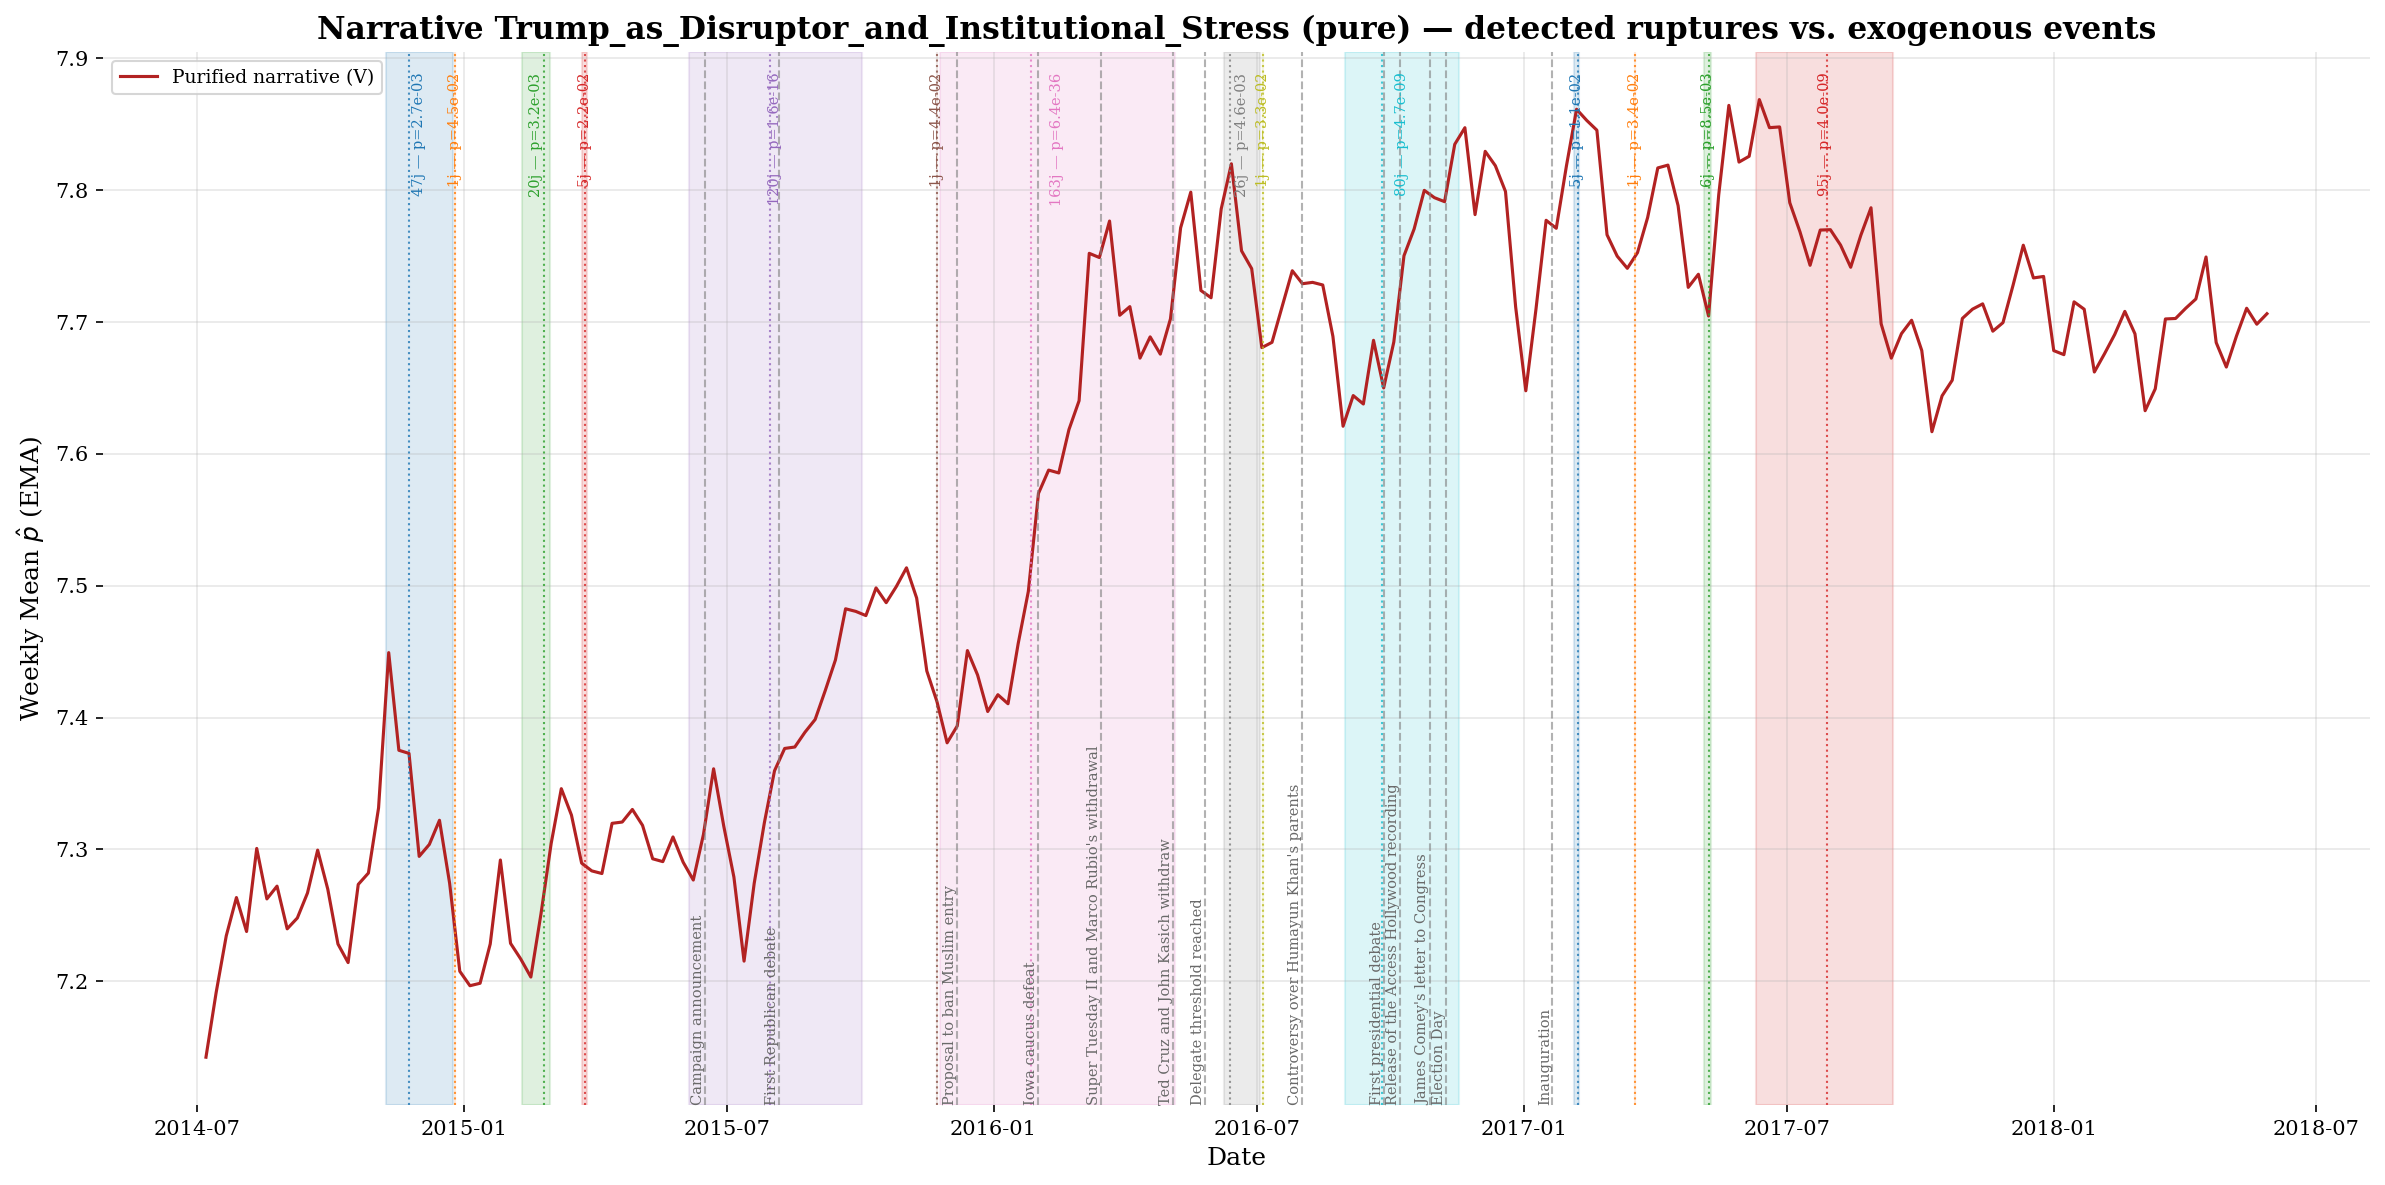

22 ruptures detected on narrative raw (N).


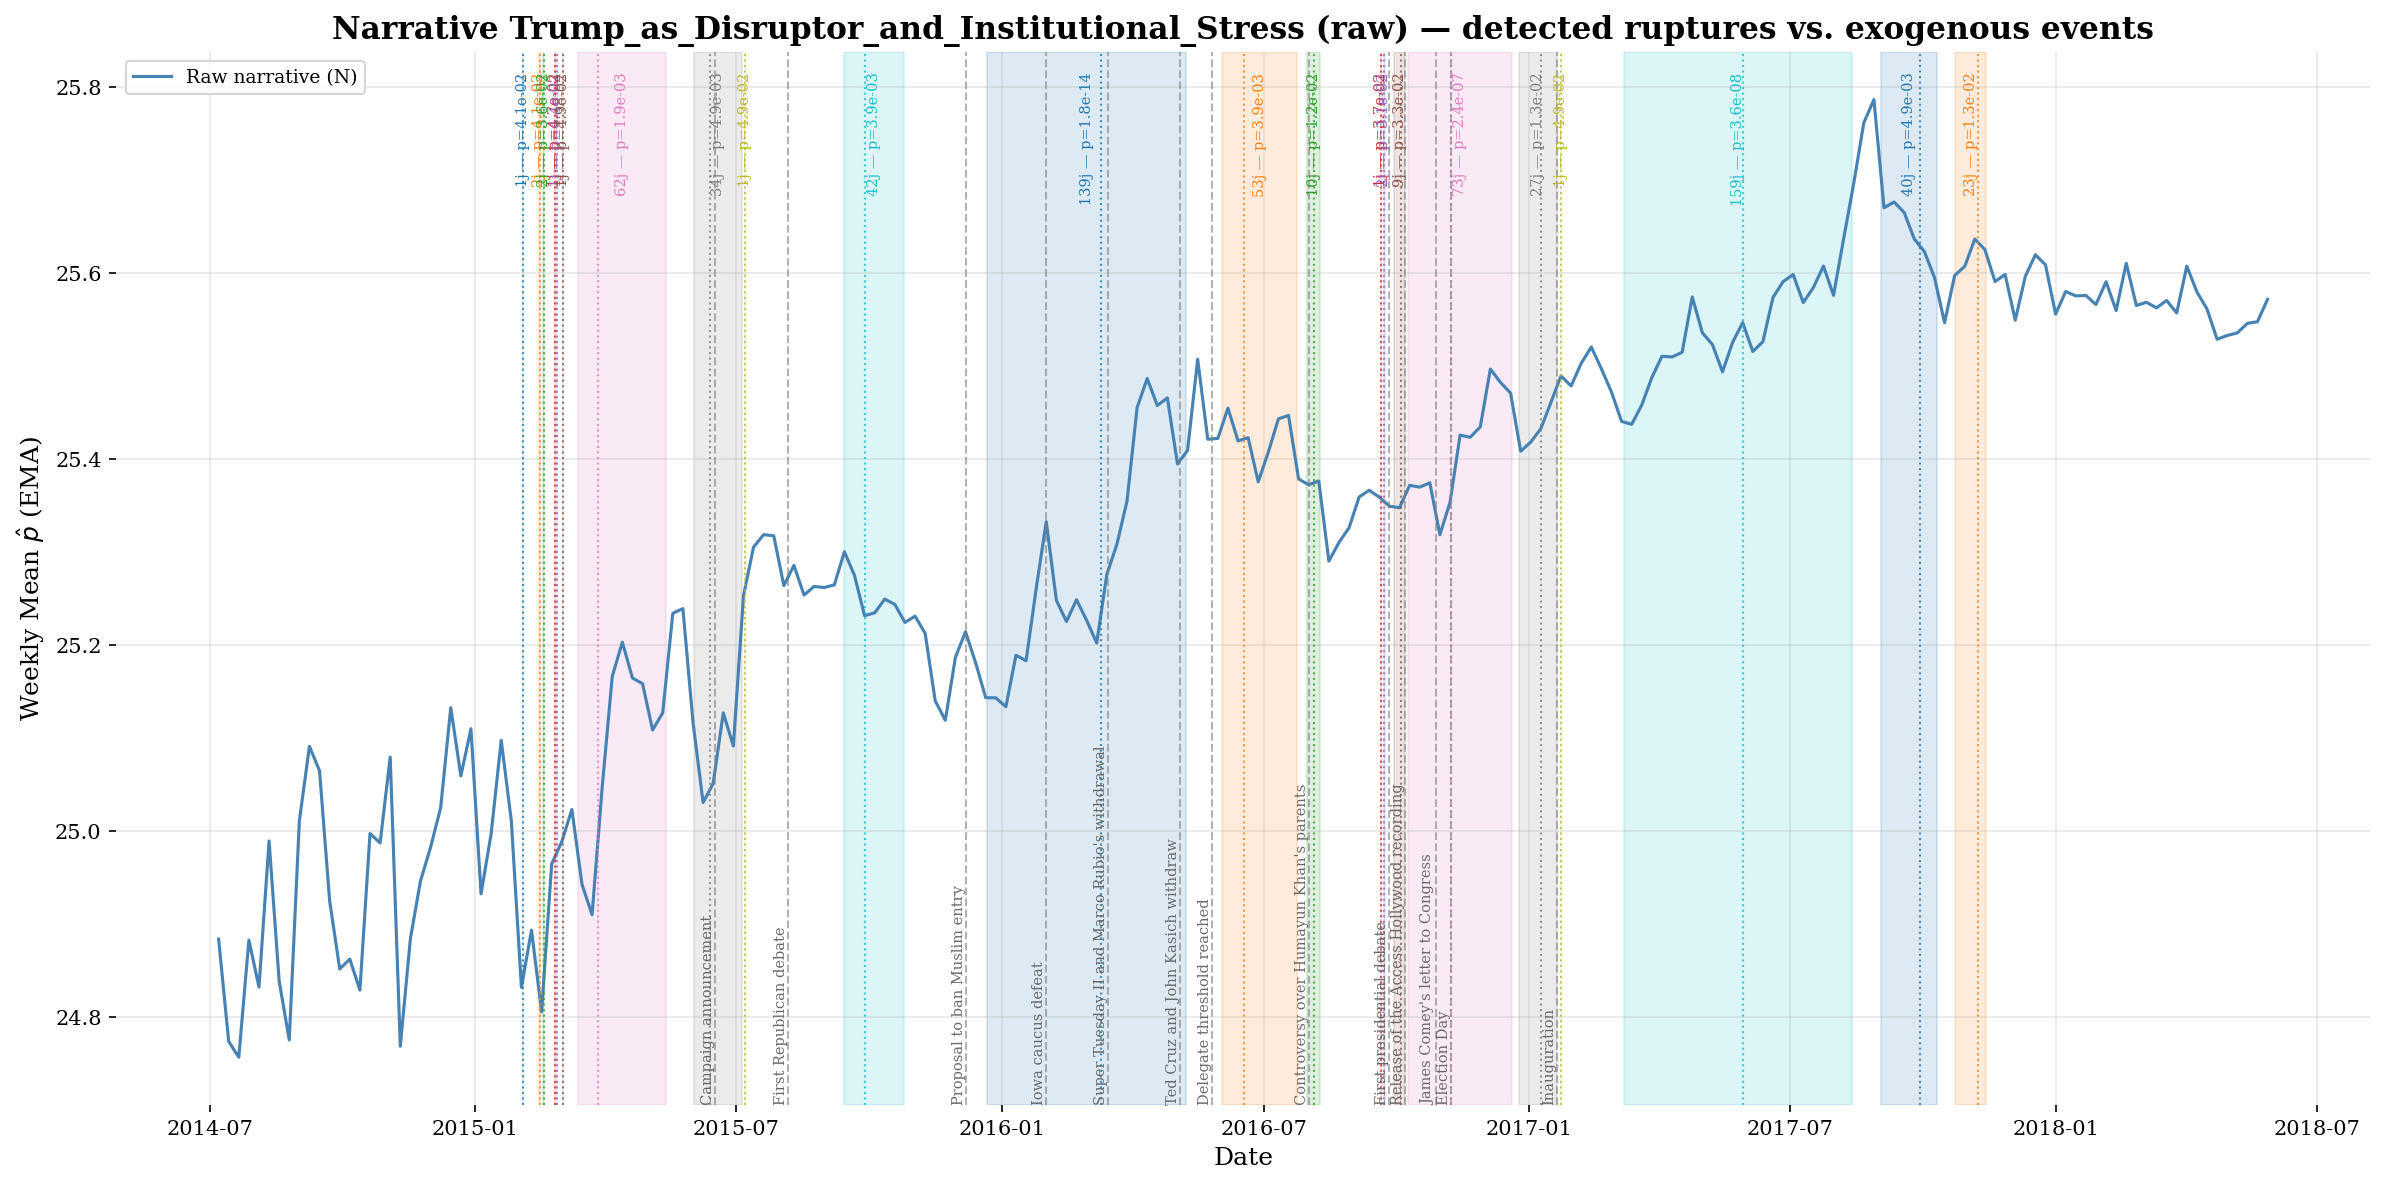

,date,label,description
0,2015-06-16,Campaign announcement,Trump officially announces his candidacy for t...
1,2015-08-06,First Republican debate,First televised Republican primary debate host...
2,2015-12-07,Proposal to ban Muslim entry,Trump calls for a total suspension of Muslims ...
3,2016-02-01,Iowa caucus defeat,Trump finishes second behind Ted Cruz in the f...
4,2016-03-15,Super Tuesday II and Marco Rubio's withdrawal,"Trump wins several primaries, including Florid..."
5,2016-05-04,Ted Cruz and John Kasich withdraw,"Following Trump's victory in Indiana on May 3,..."
6,2016-05-26,Delegate threshold reached,The Associated Press announces that Trump has ...
7,2016-08-01,Controversy over Humayun Khan's parents,Trump's remarks targeting the parents of Capta...
8,2016-09-26,First presidential debate,First televised debate between Donald Trump an...
9,2016-10-07,Release of the Access Hollywood recording,The release of a 2005 recording reveals Trump'...


In [47]:
def plot_narrative_vs_events(
    embeddings, dates, label, events, t_begin, t_end, kinds=("V", "N"),
    span_weeks=4, bandwidth_days=90, alpha=0.05, trim_days=90, min_n_days=1,
):
    """
    For one narrative, plots the EMA series of the purified (V) and/or raw (N) version
    with (i) statistically detected ruptures as coloured bands (width = length of the
    significant run, annotated with its length and FDR p-value) and (ii) known exogenous
    events as grey dashed lines. The events table is displayed once at the end.
    """
    N, V = get_narrative_vectors(label)
    results = run_moving_tests_fdr(embeddings, dates, N, V, t_begin, t_end, bandwidth_days=bandwidth_days)
    spec = {  # kind: (vector, test column, line colour, legend label, title tag)
        "V": (V, "p_delta_V", "firebrick", "Purified narrative (V)", "pure"),
        "N": (N, "p_delta_N", "steelblue", "Raw narrative (N)", "raw"),
    }
    colors = plt.cm.tab10.colors
    name = label.split(":", 1)[-1]

    for kind in kinds:
        vec, test_col, line_color, line_label, tag = spec[kind]
        _, ruptures = detect_ruptures(results, test_col=test_col, alpha=alpha, trim_days=trim_days)
        print(f"{len(ruptures)} ruptures detected on narrative {tag} ({kind}).")

        smoothed = weekly_ema(np.array([x @ vec for x in embeddings], dtype=float), dates, t_begin, t_end, span_weeks)

        fig, ax = plt.subplots(figsize=(16, 8))
        ax.plot(smoothed.index, smoothed.values, color=line_color, linewidth=1.5, label=line_label)

        # Detected ruptures: coloured bands, labels at the top
        to_plot = ruptures[ruptures["n_consecutive_days"] >= min_n_days].reset_index(drop=True)
        for i, row in to_plot.iterrows():
            color = colors[i % len(colors)]
            ax.axvspan(row["run_start"], row["run_end"], color=color, alpha=0.15)
            ax.axvline(row["rupture_date"], color=color, linestyle=":", linewidth=1.0, alpha=0.8)
            mid = row["run_start"] + (row["run_end"] - row["run_start"]) / 2
            ax.annotate(
                f"{row['n_consecutive_days']}j — p={row['p_fdr']:.1e}",
                xy=(mid, ax.get_ylim()[1]), xytext=(0, -10), textcoords="offset points",
                rotation=90, va="top", ha="center", fontsize=7, color=color,
            )

        # Exogenous events: grey dashed lines, labels at the bottom
        for date_str, ev_label, _ in events:
            date = pd.to_datetime(date_str)
            if date < smoothed.index.min() or date > smoothed.index.max():
                continue
            ax.axvline(date, color="gray", linestyle="--", alpha=0.6, linewidth=1.0)
            ax.text(date, ax.get_ylim()[0], ev_label,
                    rotation=90, va="bottom", ha="right", fontsize=7, color="dimgray")

        ax.set_title(f"Narrative {name} ({tag}) — detected ruptures vs. exogenous events",
                     fontsize=15, fontweight="bold")
        ax.set_xlabel("Date", fontsize=12)
        ax.set_ylabel("Weekly Mean $\\hat{p}$ (EMA)", fontsize=12)
        ax.legend(fontsize=9, loc="upper left")
        ax.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.savefig(f"figures/narrative_{name}_{tag}_ruptures_vs_events.pdf", dpi=300, bbox_inches="tight")
        plt.show()

    display(pd.DataFrame(events, columns=["date", "label", "description"]))


plot_narrative_vs_events(
    embeddings, dates, "politics:Trump_as_Disruptor_and_Institutional_Stress",
    TRUMP_CAMPAIGN_EVENTS, t_begin, t_end,
)

In [48]:
def analyze_narrative(embeddings, dates, label, t_begin, t_end, bandwidth_days=90, alpha=0.05, trim_days=90):
    """Une seule passe par narratif -- calcule N et V en même temps, pas de doublon."""
    N_vec, V_vec = get_narrative_vectors(label)
    results = run_moving_tests_fdr(embeddings, dates, N_vec, V_vec, t_begin, t_end, bandwidth_days=bandwidth_days)
    df_N, ruptures_N = detect_ruptures(results, test_col="p_delta_N", alpha=alpha, trim_days=trim_days)
    df_V, ruptures_V = detect_ruptures(results, test_col="p_delta_V", alpha=alpha, trim_days=trim_days)
    return {
        "sig_N": df_N.set_index("date")["significant"],
        "sig_V": df_V.set_index("date")["significant"],
        "n_ruptures_N": len(ruptures_N),
        "n_ruptures_V": len(ruptures_V),
    }


analyses = {label: analyze_narrative(embeddings, dates, label, t_begin, t_end) for label in narrative_labels}

sig_N = pd.DataFrame({label: a["sig_N"] for label, a in analyses.items()})
sig_V = pd.DataFrame({label: a["sig_V"] for label, a in analyses.items()})

breadth_N = sig_N.sum(axis=1)  
breadth_V = sig_V.sum(axis=1) 


In [49]:
def pairwise_jaccard(sig_matrix):
    labels = sig_matrix.columns
    n = len(labels)
    mat = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            a, b = sig_matrix.iloc[:, i].values, sig_matrix.iloc[:, j].values
            union = (a | b).sum()
            mat[i, j] = (a & b).sum() / union if union > 0 else np.nan
    return pd.DataFrame(mat, index=labels, columns=labels)

jaccard_N = pairwise_jaccard(sig_N)
jaccard_V = pairwise_jaccard(sig_V)

offdiag_N = upper_triangle_values(jaccard_N)
offdiag_V = upper_triangle_values(jaccard_V)

# Tableau de synthèse (même esprit que celui de la covariation)
jaccard_stats = pd.DataFrame({
    "N (brut)": [np.nanmean(offdiag_N), np.nanmedian(offdiag_N), np.nanmax(offdiag_N)],
    "V (purifié)": [np.nanmean(offdiag_V), np.nanmedian(offdiag_V), np.nanmax(offdiag_V)],
}, index=["Jaccard mean", "Jaccard median", "Jaccard max"]).round(3)

display(Markdown("### Overlap between detected ruptures by pairs of narratives (Jaccard index)"))
display(jaccard_stats)

counts_table = pd.DataFrame({
    "N (brut)": {label: a["n_ruptures_N"] for label, a in analyses.items()},
    "V (purifié)": {label: a["n_ruptures_V"] for label, a in analyses.items()},
})
display(Markdown("### Number of detected ruptures per narrative (N vs V)"))
display(counts_table)

### Overlap between detected ruptures by pairs of narratives (Jaccard index)

,N (brut),V (purifié)
Jaccard mean,0.741,0.255
Jaccard median,0.732,0.266
Jaccard max,0.919,0.536


### Number of detected ruptures per narrative (N vs V)

,N (brut),V (purifié)
politics:Trump_as_Disruptor_and_Institutional_Stress,22,14
politics:Culture_War_and_Identity_Conflict,21,13
politics:Welfare_State_Under_Press,28,21
entertainment:Entertainment_as_Political_Resistance,28,18
entertainment:Franchise_Nostalgia_and_Serial_Dominance,33,16
entertainment:Celebrity_Image_Management_in_the_Social_Media_Age,28,13
parenting:The_Overwhelmed_Modern_Parent,32,12
parenting:Intensive_and_Expert_Guided_Parenting,26,18
parenting:Raising_Children_in_a_Politicized_Society,23,23
travel:Experiential_and_Transformational_Travel,29,17
